# Home Credit Default Risk Dataset Project

# Part 3 - All Data and Statistical Inference

This is Part 3 of the Home Credit Project for Machine Learning Capstone Project project of Machine Learning module sprint 4. 

In this part, the entire dataset will be explored in detail.
- All correlation coefficients will be calculated.
- For the additional CSV files included in this project, charts illustrating the relationship between each feature and the target variable will be drawn.
- Hypothesis testing will be performed on all features with respect to the target variable.

The objective is not only to identify features that may be most strongly related to the target, but also to remove highly correlated features and those with high p-values after statistical inference. This is done to optimize performance given the limited computing resources available

# Initial Setup: Imports and Data Merge

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb as db
import statsmodels.api as sm
from sklearn.preprocessing import OneHotEncoder
from scripts import *

pd.set_option('display.max_rows', 300)

In [2]:
app_train = pd.read_csv('home-credit-default-risk/application_train.csv')
bureau_balance = pd.read_csv('home-credit-default-risk/bureau_balance.csv')
bureau = pd.read_csv('home-credit-default-risk/bureau.csv')
credit_card_balance = pd.read_csv('home-credit-default-risk/credit_card_balance.csv')
installments_payments = pd.read_csv('home-credit-default-risk/installments_payments.csv')
pos_cash = pd.read_csv('home-credit-default-risk/POS_CASH_balance.csv')
previous_application = pd.read_csv('home-credit-default-risk/previous_application.csv')

## Data Preparation

### Application Data

In [3]:
mask = app_train.DAYS_EMPLOYED == 365243
app_train['NAME_INCOME_TYPE'][mask].unique()

app_train.loc[mask, 'OCCUPATION_TYPE'] = app_train.loc[mask, 'OCCUPATION_TYPE'].fillna('Not employed')
app_train['OCCUPATION_TYPE'] = app_train['OCCUPATION_TYPE'].fillna('Unknown')

app_train['CAR_AGE_WAS_64'] = (app_train['OWN_CAR_AGE'] == 64).astype(int)
app_train['OWN_CAR_AGE'] = app_train['OWN_CAR_AGE'].replace(64, np.nan)

# Replace suspiciously high values the realistic median
mask = app_train['AMT_INCOME_TOTAL'] < 2e7, 'AMT_INCOME_TOTAL'
realistic_median = app_train.loc[mask].median()
mask = app_train['AMT_INCOME_TOTAL'] > 2e7, 'AMT_INCOME_TOTAL'
app_train.loc[mask] = realistic_median

realistic_median_def_30 = app_train.loc[app_train['DEF_30_CNT_SOCIAL_CIRCLE'] < 10, 'DEF_30_CNT_SOCIAL_CIRCLE'].median()
app_train.loc[app_train['DEF_30_CNT_SOCIAL_CIRCLE'] >= 10, 'DEF_30_CNT_SOCIAL_CIRCLE'] = realistic_median_def_30

realistic_median_obs_60 = app_train.loc[app_train['OBS_60_CNT_SOCIAL_CIRCLE'] < 31, 'OBS_60_CNT_SOCIAL_CIRCLE'].median()
realistic_median_def_60 = app_train.loc[app_train['DEF_60_CNT_SOCIAL_CIRCLE'] < 10, 'DEF_60_CNT_SOCIAL_CIRCLE'].median()
app_train.loc[app_train['OBS_60_CNT_SOCIAL_CIRCLE'] >= 31, 'OBS_60_CNT_SOCIAL_CIRCLE'] = realistic_median_obs_60
app_train.loc[app_train['DEF_60_CNT_SOCIAL_CIRCLE'] >= 10, 'DEF_60_CNT_SOCIAL_CIRCLE'] = realistic_median_def_60

app_train['DAYS_LAST_PHONE_CHANGE'] = app_train['DAYS_LAST_PHONE_CHANGE'].replace(0, np.nan)
app_train['PHONE_CHANGE_SUS_FLAG'] = (app_train['DAYS_LAST_PHONE_CHANGE'].isna()).astype(int)

realistic_median_amt_req = app_train.loc[
    app_train['AMT_REQ_CREDIT_BUREAU_QRT'] < 20, 'OBS_60_CNT_SOCIAL_CIRCLE'
].median()
app_train.loc[app_train['AMT_REQ_CREDIT_BUREAU_QRT'] >= 20, 'AMT_REQ_CREDIT_BUREAU_QRT'] = realistic_median_amt_req

for col in ['EXT_SOURCE_1', 'EXT_SOURCE_3']:
    app_train[f'{col}_MISSING'] = app_train[col].isnull().astype(int)

building_avg = [
    'APARTMENTS_AVG',
    'BASEMENTAREA_AVG',
    'YEARS_BEGINEXPLUATATION_AVG',
    'YEARS_BUILD_AVG',
    'COMMONAREA_AVG',
    'ELEVATORS_AVG',
    'ENTRANCES_AVG',
    'FLOORSMAX_AVG',
    'FLOORSMIN_AVG',
    'LANDAREA_AVG',
    'LIVINGAPARTMENTS_AVG',
    'LIVINGAREA_AVG',
    'NONLIVINGAPARTMENTS_AVG',
    'NONLIVINGAREA_AVG',
]

building_other = ['FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'TOTALAREA_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']

app_train['MISSING_BUREAU_REQ'] = app_train['AMT_REQ_CREDIT_BUREAU_QRT'].isnull().astype(int)
app_train['BUILDING_MISSING_COUNT'] = app_train[building_avg].isna().sum(axis=1)
app_train['BUILDING_ANY_MISSING'] = (app_train['BUILDING_MISSING_COUNT'] >= 1).astype(int)
app_train['BUILDING_OTHER_MISSING_COUNT'] = app_train[building_other].isna().sum(axis=1)
app_train['BUILDING_OTHER_ANY_MISSING'] = (app_train['BUILDING_OTHER_MISSING_COUNT'] >= 1).astype(int)

# Select all FLAG_DOCUMENT_* columns
flag_doc_cols = [col for col in app_train.columns if col.startswith('FLAG_DOCUMENT_')]

# Create a new column that is 1 if any document flag is 1, else 0
app_train['ANY_DOCUMENT_PRESENTED'] = app_train[flag_doc_cols].any(axis=1).astype(int)
app_train['DOCUMENTS_COUNT'] = app_train[flag_doc_cols].sum(axis=1)

app_train['CREDIT_INCOME_RATIO'] = app_train['AMT_CREDIT'] / app_train['AMT_INCOME_TOTAL']
app_train['ANNUITY_INCOME_RATIO'] = app_train['AMT_ANNUITY'] / app_train['AMT_INCOME_TOTAL']
app_train['ANNUITY_CREDIT_RATIO'] = app_train['AMT_ANNUITY'] / app_train['AMT_CREDIT']
app_train['GOODS_CREDIT_RATIO'] = app_train['AMT_GOODS_PRICE'] / app_train['AMT_CREDIT']

app_train['DAYS_EMPLOYED'] = app_train['DAYS_EMPLOYED'].replace(365243, np.nan)
app_train['AGE_YEARS'] = (-app_train['DAYS_BIRTH']) // 365
app_train['YEARS_EMPLOYED'] = app_train['DAYS_EMPLOYED'].apply(lambda x: x if x < 0 else np.nan) / -365
app_train['RECENT_PHONE_CHANGE'] = (app_train['DAYS_LAST_PHONE_CHANGE'] > -365).astype(int)

columns_to_drop = [
    'FLAG_MOBIL',
    'FLAG_DOCUMENT_2',
    'FLAG_DOCUMENT_4',
    'FLAG_DOCUMENT_7',
    'FLAG_DOCUMENT_10',
    'FLAG_DOCUMENT_12',
    'FLAG_DOCUMENT_21',
    'OBS_30_CNT_SOCIAL_CIRCLE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'FLAG_EMP_PHONE',
    'FLAG_DOCUMENT_5',
    'FLAG_CONT_MOBILE',
    'FLAG_DOCUMENT_20',
]
app_train = app_train.drop(columns_to_drop, axis=1)

app_train['FLAG_OWN_CAR'] = app_train['FLAG_OWN_CAR'].map({'Y': 1, 'N': 0})
app_train['FLAG_OWN_REALTY'] = app_train['FLAG_OWN_REALTY'].map({'Y': 1, 'N': 0})

app_train['NAME_TYPE_SUITE_OTHER'] = (
    app_train['NAME_TYPE_SUITE'].isin(['Other_A', 'Other_B', 'Group of people']).astype(int)
)

app_train['NAME_EDUCATION_TYPE_SECONDARY'] = (
    app_train['NAME_EDUCATION_TYPE'].isin(['Secondary / secondary special', 'Lower secondary']).astype(int)
)

app_train['WALLSMATERIAL_MODE_UNCOMMON'] = (
    app_train['WALLSMATERIAL_MODE'].isin(['Block', 'Mixed', 'Wooden', 'Others', 'Monolithic']).astype(int)
)

occupation_map = {
    'Laborers': 'Manual',
    'Low-skill Laborers': 'Manual',
    'Drivers': 'Manual',
    'Cleaning staff': 'Manual',
    'Cooking staff': 'Manual',
    'Security staff': 'Manual',
    'Core staff': 'Office',
    'Secretaries': 'Office',
    'HR staff': 'Office',
    'Accountants': 'Professional',
    'Managers': 'Professional',
    'IT staff': 'Professional',
    'High skill tech staff': 'Professional',
    'Medicine staff': 'Professional',
    'Sales staff': 'Service',
    'Waiters/barmen staff': 'Service',
    'Private service staff': 'Service',
    'Realty agents': 'Service',
    'Not employed': 'Unemployed',
    'Unknown': 'Unemployed',
}

app_train['OCCUPATION_TYPE_GROUPED'] = app_train['OCCUPATION_TYPE'].map(occupation_map)

app_train['ORGANIZATION_TYPE_TRADE'] = app_train['ORGANIZATION_TYPE'].str.contains('Trade', case=False).astype(int)
app_train['ORGANIZATION_TYPE_INDUSTRY'] = (
    app_train['ORGANIZATION_TYPE'].str.contains('Industry', case=False).astype(int)
)
app_train['ORGANIZATION_TYPE_TRANSPORT'] = (
    app_train['ORGANIZATION_TYPE'].str.contains('Transport', case=False).astype(int)
)
app_train['ORGANIZATION_TYPE_BUSINESS_ENTITY'] = (
    app_train['ORGANIZATION_TYPE'].str.contains('Business Entity Type', case=False).astype(int)
)
app_train['ORGANIZATION_TYPE_GOVERNMENT'] = (
    app_train['ORGANIZATION_TYPE']
    .isin(['Government', 'Military', 'Police', 'Emergency', 'Security Ministries', 'Postal'])
    .astype(int)
)
app_train['ORGANIZATION_TYPE_EDUCATION'] = (
    app_train['ORGANIZATION_TYPE'].isin(['School', 'University', 'Kindergarten']).astype(int)
)
app_train['ORGANIZATION_TYPE_INFRASTRUCTURE'] = (
    app_train['ORGANIZATION_TYPE'].isin(['Construction', 'Housing', 'Electricity']).astype(int)
)
app_train['ORGANIZATION_TYPE_SERVICES'] = (
    app_train['ORGANIZATION_TYPE']
    .isin(['Self-employed', 'Services', 'Cleaning', 'Legal Services', 'Realtor', 'Security', 'Religion'])
    .astype(int)
)
app_train['ORGANIZATION_TYPE_FINANCE'] = app_train['ORGANIZATION_TYPE'].isin(['Bank', 'Insurance']).astype(int)
app_train['ORGANIZATION_TYPE_TECH'] = (
    app_train['ORGANIZATION_TYPE'].isin(['Telecom', 'Mobile', 'Advertising']).astype(int)
)
app_train['ORGANIZATION_TYPE_HOSPITALITY'] = (
    app_train['ORGANIZATION_TYPE'].isin(['Restaurant', 'Hotel', 'Culture']).astype(int)
)

x_num = app_train.select_dtypes(exclude='object').reset_index(drop=True)
x_cat = app_train.select_dtypes(include='object')

encoder = OneHotEncoder(sparse_output=False)
x_encoded = encoder.fit_transform(x_cat)

# create the names for the one-hot encoded categorical features
categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

# put the features into a dataframe and join with the original
# numerical features

one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)

# Dropping missing and some of rare categories
one_hot_features = one_hot_features.drop(
    [
        'EMERGENCYSTATE_MODE_nan',
        'CODE_GENDER_XNA',
        'FONDKAPREMONT_MODE_nan',
        'HOUSETYPE_MODE_nan',
        'WALLSMATERIAL_MODE_nan',
        'ORGANIZATION_TYPE_XNA',
        'NAME_TYPE_SUITE_nan',
        'NAME_TYPE_SUITE_Group of people',
        'NAME_TYPE_SUITE_Other_A',
        'NAME_INCOME_TYPE_Businessman',
        'NAME_INCOME_TYPE_Maternity leave',
        'NAME_INCOME_TYPE_Student',
        'NAME_INCOME_TYPE_Unemployed',
        'NAME_FAMILY_STATUS_Unknown',
        'NAME_HOUSING_TYPE_Co-op apartment',
        'OCCUPATION_TYPE_Unknown',
        'FONDKAPREMONT_MODE_not specified',
        'WALLSMATERIAL_MODE_Monolithic',
        'NAME_INCOME_TYPE_Pensioner',
        'CODE_GENDER_F',
        'NAME_CONTRACT_TYPE_Revolving loans',
        'OCCUPATION_TYPE_Realty agents',
        'ORGANIZATION_TYPE_Advertising',
        'ORGANIZATION_TYPE_Business Entity Type 1',
        'ORGANIZATION_TYPE_Industry: type 6',
        'ORGANIZATION_TYPE_Industry: type 7',
        'ORGANIZATION_TYPE_Telecom',
        'ORGANIZATION_TYPE_Transport: type 2',
        'ORGANIZATION_TYPE_Trade: type 5',
        'ORGANIZATION_TYPE_Housing',
        'ORGANIZATION_TYPE_Legal Services',
    ],
    axis=1,
)
app_train_enc = x_num.join(one_hot_features)

# Putting Transported column last for convience
cols = app_train_enc.columns.tolist()
cols = cols[:1] + cols[2:] + cols[1:2]

app_train_enc = app_train_enc[cols]
app_train_enc.head(10).T

,0,1,2,3,4,5,6,7,8,9
SK_ID_CURR,100002.000000,1.000030e+05,100004.000000,100006.000000,100007.000000,100008.000000,1.000090e+05,1.000100e+05,1.000110e+05,100012.000000
FLAG_OWN_CAR,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00,0.000000e+00,0.000000
FLAG_OWN_REALTY,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000
CNT_CHILDREN,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000e+00,0.000000e+00,0.000000
AMT_INCOME_TOTAL,202500.000000,2.700000e+05,67500.000000,135000.000000,121500.000000,99000.000000,1.710000e+05,3.600000e+05,1.125000e+05,135000.000000
AMT_CREDIT,406597.500000,1.293502e+06,135000.000000,312682.500000,513000.000000,490495.500000,1.560726e+06,1.530000e+06,1.019610e+06,405000.000000
AMT_ANNUITY,24700.500000,3.569850e+04,6750.000000,29686.500000,21865.500000,27517.500000,4.130100e+04,4.207500e+04,3.382650e+04,20250.000000
AMT_GOODS_PRICE,351000.000000,1.129500e+06,135000.000000,297000.000000,513000.000000,454500.000000,1.395000e+06,1.530000e+06,9.135000e+05,405000.000000
REGION_POPULATION_RELATIVE,0.018801,3.541000e-03,0.010032,0.008019,0.028663,0.035792,3.579200e-02,3.122000e-03,1.863400e-02,0.019689
DAYS_REGISTRATION,-3648.000000,-1.186000e+03,-4260.000000,-9833.000000,-4311.000000,-4970.000000,-1.213000e+03,-4.597000e+03,-7.427000e+03,-14437.000000


### Bureau

In [4]:
bureau['CREDIT_ENDDATE_MISSING_FLAG'] = bureau['DAYS_CREDIT_ENDDATE'].isnull().astype(int)
bureau['ENDDATE_FACT_MISSING_FLAG'] = bureau['DAYS_ENDDATE_FACT'].isnull().astype(int)
bureau['AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG'] = bureau['AMT_CREDIT_MAX_OVERDUE'].isnull().astype(int)
bureau['HAS_ANNUITY_INFO'] = bureau['AMT_ANNUITY'].notnull().astype(int)


def simplify_credit_type(x: str) -> str:
    """
    Helper function to simplify credit type into broader categories.
    Keeps 'Consumer credit', 'Credit card', 'Car loan', and 'Mortgage' as-is.

    Parameters: x (str): original credit type.
    Returns: str: Simplified credit type.
    """
    if x in ['Consumer credit', 'Credit card', 'Car loan', 'Mortgage']:
        return x
    else:
        return 'Other'


def simplify_credit_active(x: str) -> str:
    """
    Helper function to simplify credit active into broader categories.
    Keeps 'Closed' and 'Active' as-is.

    Parameters: x (str): original credit type.
    Returns: str: Simplified credit category.
    """
    if x in ['Closed', 'Active']:
        return x
    else:
        return 'Other'


bureau['CREDIT_TYPE_GROUPED'] = bureau['CREDIT_TYPE'].apply(simplify_credit_type)
bureau['CREDIT_ACTIVE_GROUPED'] = bureau['CREDIT_ACTIVE'].apply(simplify_credit_active)
bureau['CREDIT_CURRENCY_GROUPED'] = bureau['CREDIT_CURRENCY'].apply(
    lambda x: 'currency 1' if x == 'currency 1' else 'other currency'
)
bureau['WAS_CREDIT_PROLONGED'] = (bureau['CNT_CREDIT_PROLONG'] != 0).astype(int)

bureau['CREDIT_LENGTH'] = bureau['DAYS_ENDDATE_FACT'] - bureau['DAYS_CREDIT']
bureau['DEBT_CREDIT_RATIO'] = bureau.apply(
    lambda row: row['AMT_CREDIT_SUM_DEBT'] / row['AMT_CREDIT_SUM'] if row['AMT_CREDIT_SUM'] != 0 else np.nan, axis=1
)
bureau['OVERDUE_TO_DEBT_RATIO'] = bureau.apply(
    lambda row: (
        row['AMT_CREDIT_SUM_OVERDUE'] / row['AMT_CREDIT_SUM_DEBT'] if row['AMT_CREDIT_SUM_DEBT'] != 0 else np.nan
    ),
    axis=1,
)
bureau['HAS_OVERDUE'] = (bureau['AMT_CREDIT_SUM_OVERDUE'] > 0).astype(int)
bureau['CREDIT_ACTIVE_FLAG'] = bureau['CREDIT_ACTIVE'].isin(['Active']).astype(int)

bureau['OVERDUE_WITH_NO_DEBT_FLAG'] = (
    (bureau['AMT_CREDIT_SUM_DEBT'] == 0) & (bureau['AMT_CREDIT_SUM_OVERDUE'] > 0)
).astype(int)

mask = bureau['CREDIT_LENGTH'] < 0
bureau.loc[mask, 'CREDIT_LENGTH'] = np.nan

query = """
    SELECT 
        SK_ID_BUREAU,
        AVG(MONTHS_BALANCE) MONTHS_BALANCE,
        CASE 
            WHEN COUNT_IF(STATUS IN ('0','1','2','3','4','5')) > 0 
                THEN MAX(CASE WHEN STATUS IN ('0','1','2','3','4','5') 
                THEN STATUS ELSE NULL END)
            WHEN COUNT_IF(STATUS = 'C') > 0 
                THEN 'C'
            ELSE 'X'
        END AS STATUS
    FROM bureau_balance
    GROUP BY SK_ID_BUREAU;    
"""

bb_agg = db.sql(query).df()
query = '''
SELECT *
FROM bureau b
LEFT JOIN bb_agg bb
ON b.SK_ID_BUREAU = bb.SK_ID_BUREAU
'''

bureau_all = db.sql(query).df().drop(['SK_ID_BUREAU_1'], axis=1)

aggregations = {
    'DAYS_CREDIT': ['mean'],
    'CREDIT_DAY_OVERDUE': ['mean', 'max'],
    'DAYS_CREDIT_ENDDATE': ['mean'],
    'DAYS_ENDDATE_FACT': ['min', 'mean'],
    'AMT_CREDIT_MAX_OVERDUE': ['mean'],
    'CNT_CREDIT_PROLONG': ['mean', 'max'],
    'AMT_CREDIT_SUM': ['mean'],
    'AMT_CREDIT_SUM_DEBT': ['mean'],
    'AMT_CREDIT_SUM_LIMIT': ['mean'],
    'AMT_CREDIT_SUM_OVERDUE': ['mean'],
    'DAYS_CREDIT_UPDATE': ['mean'],
    'AMT_ANNUITY': ['mean'],
    'CREDIT_ENDDATE_MISSING_FLAG': ['max'],
    'ENDDATE_FACT_MISSING_FLAG': ['max'],
    'AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG': ['max'],
    'HAS_ANNUITY_INFO': ['max'],
    'WAS_CREDIT_PROLONGED': ['max'],
    'CREDIT_LENGTH': ['mean', 'max'],
    'DEBT_CREDIT_RATIO': ['mean'],
    'OVERDUE_TO_DEBT_RATIO': ['mean'],
    'HAS_OVERDUE': ['max'],
    'CREDIT_ACTIVE_FLAG': ['max'],
    'OVERDUE_WITH_NO_DEBT_FLAG': ['max'],
    'MONTHS_BALANCE': ['mean'],
}

bureau_agg = bureau_all.groupby('SK_ID_CURR').agg(aggregations)
bureau_agg.columns = ['BUR_' + '_'.join(col).upper() for col in bureau_agg.columns]
bureau_agg.reset_index(inplace=True)

query = '''
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_BUREAU) AS NUM_BUREAU,
        CASE WHEN COUNT(DISTINCT SK_ID_BUREAU) > 0 THEN 1 ELSE 0 END AS HAS_BUREAU,
       
        SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Active' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_ACTIVE,
        SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Closed' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_CLOSED,
        SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Other' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_OTHER,

        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Credit card' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CREDIT_CARD,
        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Consumer credit' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CONSUMER_CREDIT,
        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Mortgage' THEN 1 ELSE 0 END) AS CREDIT_TYPE_MORTGAGE,
        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Car loan' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CAR_LOAN,
        SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Other' THEN 1 ELSE 0 END) AS CREDIT_TYPE_OTHER,
        
        COUNT(DISTINCT CREDIT_CURRENCY) AS NUM_DISTINCT_CURRENCIES,
        SUM(CASE WHEN CREDIT_CURRENCY = 'currency 1' THEN 1 ELSE 0 END) AS NUM_CURRENCY_1,
        SUM(CASE WHEN CREDIT_CURRENCY = 'currency 2' THEN 1 ELSE 0 END) AS NUM_CURRENCY_2,
        SUM(CASE WHEN CREDIT_CURRENCY = 'currency 3' THEN 1 ELSE 0 END) AS NUM_CURRENCY_3,
        SUM(CASE WHEN CREDIT_CURRENCY_GROUPED = 'other currency' THEN 1 ELSE 0 END) AS NUM_CURRENCY_OTHER,
        CASE 
            WHEN COUNT_IF(STATUS IN ('0','1','2','3','4','5')) > 0 
                THEN MAX(CASE WHEN STATUS IN ('0','1','2','3','4','5') 
                THEN STATUS ELSE NULL END)
            WHEN COUNT_IF(STATUS = 'C') > 0 
                THEN 'C'
            ELSE 'X'
        END AS STATUS,
        CASE 
            WHEN COUNT(*) FILTER (WHERE STATUS IN ('1','2','3','4','5')) > 0 
                THEN 1
            ELSE 0
        END AS STATUS_FLAG
    FROM bureau_all
    GROUP BY SK_ID_CURR
    )
    
SELECT *
FROM bureau_agg b
LEFT JOIN t1
ON b.SK_ID_CURR = t1.SK_ID_CURR
'''

bureau_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)

x_num = bureau_agg.select_dtypes(exclude='object').reset_index(drop=True)
x_cat = bureau_agg.select_dtypes(include='object')

encoder = OneHotEncoder(sparse_output=False)
x_encoded = encoder.fit_transform(x_cat)

# create the names for the one-hot encoded categorical features
categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

# put the features into a dataframe and join with the original
# numerical features
one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)

# Dropping missing and some of rare categories
one_hot_features = one_hot_features.drop(['STATUS_X'], axis=1)

bureau_agg = x_num.join(one_hot_features)

# Replace suspiciously value with the realistic median
mask = bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] < 2e7
realistic_median = bureau_agg.loc[mask, 'BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'].median()
mask = bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] > 2e7
bureau_agg.loc[mask, 'BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] = realistic_median

mask = bureau_agg['BUR_AMT_CREDIT_SUM_MEAN'] < 5e7
realistic_median = bureau_agg.loc[mask, 'BUR_AMT_CREDIT_SUM_MEAN'].median()
mask = bureau_agg['BUR_AMT_CREDIT_SUM_MEAN'] > 5e7
bureau_agg.loc[mask, 'BUR_AMT_CREDIT_SUM_MEAN'] = realistic_median

bureau_agg.head()

,SK_ID_CURR,BUR_DAYS_CREDIT_MEAN,BUR_CREDIT_DAY_OVERDUE_MEAN,BUR_CREDIT_DAY_OVERDUE_MAX,BUR_DAYS_CREDIT_ENDDATE_MEAN,BUR_DAYS_ENDDATE_FACT_MIN,BUR_DAYS_ENDDATE_FACT_MEAN,BUR_AMT_CREDIT_MAX_OVERDUE_MEAN,BUR_CNT_CREDIT_PROLONG_MEAN,BUR_CNT_CREDIT_PROLONG_MAX,...,NUM_CURRENCY_3,NUM_CURRENCY_OTHER,STATUS_FLAG,STATUS_0,STATUS_1,STATUS_2,STATUS_3,STATUS_4,STATUS_5,STATUS_C
0,237254,-235.000000,0.000000,0,3418.000000,NaN,NaN,NaN,0.0,0,...,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,355550,-1279.666667,43.666667,131,-993.000000,-2098.0,-1168.5,NaN,0.0,0,...,0.0,0.0,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,380762,-1933.000000,0.000000,0,8208.714286,-2560.0,-1783.0,2646.00,0.0,0,...,0.0,0.0,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,112392,-860.000000,0.000000,0,-494.750000,-1109.0,-873.0,NaN,0.0,0,...,0.0,0.0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,360631,-1059.666667,0.000000,0,9596.333333,-2046.0,-1123.5,6035.04,0.0,0,...,0.0,0.0,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0


### POS Cash Balance

In [5]:
pos_cash['HAD_DPD'] = pos_cash['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
pos_cash['HAD_DPD_DEF'] = pos_cash['SK_DPD_DEF'].apply(lambda x: 1 if x > 0 else 0)

aggregations = {
    'MONTHS_BALANCE': ['min', 'mean'],
    'CNT_INSTALMENT': ['mean', 'max'],
    'CNT_INSTALMENT_FUTURE': ['mean', 'sum'],
    'SK_DPD': ['mean', 'max'],
    'SK_DPD_DEF': ['mean', 'max'],
    'HAD_DPD': ['max'],
    'HAD_DPD_DEF': ['max'],
}

pos_agg = pos_cash.groupby('SK_ID_CURR').agg(aggregations)
pos_agg.columns = ['POS_' + '_'.join(col).upper() for col in pos_agg.columns]
pos_agg.reset_index(inplace=True)

query = """
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_PREV) AS NUM_PREVIOUS_POS_LOANS,
        CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAS_PREVIOUS_POS
    FROM pos_cash
    GROUP BY SK_ID_CURR
    ), 

    t2 as (
    SELECT 
    SK_ID_CURR,
    COUNT(DISTINCT CASE WHEN has_active = 1 THEN SK_ID_PREV ELSE NULL END) AS POS_ACTIVE_LOANS,
    FROM (
        SELECT 
            SK_ID_CURR,
            SK_ID_PREV,
            MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Active' THEN 1 ELSE 0 END) AS has_active,
        FROM pos_cash
        GROUP BY SK_ID_CURR, SK_ID_PREV
    ) AS loan_flags
    GROUP BY SK_ID_CURR
    )

SELECT *
FROM pos_agg pa
JOIN t1
ON pa.SK_ID_CURR = t1.SK_ID_CURR
LEFT JOIN t2
ON pa.SK_ID_CURR = t2.SK_ID_CURR;
"""

pos_agg = db.sql(query).df().drop(['SK_ID_CURR_1', 'SK_ID_CURR_2'], axis=1)
pos_agg.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,SK_ID_CURR,POS_MONTHS_BALANCE_MIN,POS_MONTHS_BALANCE_MEAN,POS_CNT_INSTALMENT_MEAN,POS_CNT_INSTALMENT_MAX,POS_CNT_INSTALMENT_FUTURE_MEAN,POS_CNT_INSTALMENT_FUTURE_SUM,POS_SK_DPD_MEAN,POS_SK_DPD_MAX,POS_SK_DPD_DEF_MEAN,POS_SK_DPD_DEF_MAX,POS_HAD_DPD_MAX,POS_HAD_DPD_DEF_MAX,NUM_PREVIOUS_POS_LOANS,HAS_PREVIOUS_POS,POS_ACTIVE_LOANS
0,276557,-95,-35.278351,25.494845,60.0,18.546392,1799.0,0.216495,21,0.0,0,1,0,9,1,9
1,212153,-44,-22.264151,21.981132,60.0,16.754717,888.0,0.000000,0,0.0,0,0,0,6,1,6
2,437848,-96,-33.928571,17.023810,24.0,11.000000,462.0,0.000000,0,0.0,0,0,0,4,1,4
3,350037,-27,-13.460000,17.220000,24.0,10.940000,547.0,0.000000,0,0.0,0,0,0,4,1,4
4,149226,-51,-21.723684,45.000000,60.0,29.644737,2253.0,0.000000,0,0.0,0,0,0,3,1,3


### Credit Card Balance

In [6]:
credit_card_balance['HAD_DPD'] = credit_card_balance['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
credit_card_balance['HAD_DPD_DEF'] = credit_card_balance['SK_DPD_DEF'].apply(lambda x: 1 if x > 0 else 0)

aggregations = {
    'MONTHS_BALANCE': ['min', 'mean'],
    'AMT_BALANCE': ['mean'],
    'AMT_CREDIT_LIMIT_ACTUAL': ['mean'],
    'AMT_DRAWINGS_ATM_CURRENT': ['mean'],
    'AMT_DRAWINGS_CURRENT': ['mean'],
    'AMT_DRAWINGS_OTHER_CURRENT': ['mean'],
    'AMT_DRAWINGS_POS_CURRENT': ['mean'],
    'AMT_INST_MIN_REGULARITY': ['mean'],
    'AMT_PAYMENT_CURRENT': ['mean'],
    'AMT_PAYMENT_TOTAL_CURRENT': ['mean'],
    'AMT_RECEIVABLE_PRINCIPAL': ['mean'],
    'AMT_RECIVABLE': ['mean'],
    'AMT_TOTAL_RECEIVABLE': ['mean'],
    'CNT_DRAWINGS_ATM_CURRENT': ['mean'],
    'CNT_DRAWINGS_CURRENT': ['mean'],
    'CNT_DRAWINGS_OTHER_CURRENT': ['mean'],
    'CNT_DRAWINGS_POS_CURRENT': ['mean'],
    'CNT_INSTALMENT_MATURE_CUM': ['mean'],
    'SK_DPD': ['mean'],
    'SK_DPD_DEF': ['mean'],
    'HAD_DPD': ['max'],
    'HAD_DPD_DEF': ['max'],
}

cc_bal_agg = credit_card_balance.groupby('SK_ID_CURR').agg(aggregations)
cc_bal_agg.columns = ['CC_' + '_'.join(col).upper() for col in cc_bal_agg.columns]
cc_bal_agg.reset_index(inplace=True)

query = """
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_PREV) AS NUM_CREDIT_CARD,
        CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAS_PREVIOUS_CREDIT_CARD
    FROM credit_card_balance
    GROUP BY SK_ID_CURR
    ), 

    t2 as (
    SELECT 
    SK_ID_CURR,
    COUNT(DISTINCT CASE WHEN has_active = 1 THEN SK_ID_PREV ELSE NULL END) AS CC_ACTIVE,
    COUNT(DISTINCT CASE WHEN has_completed = 1 THEN SK_ID_PREV ELSE NULL END) AS CC_COMPLETED,
    FROM (
        SELECT 
            SK_ID_CURR,
            SK_ID_PREV,
            MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Active' THEN 1 ELSE 0 END) AS has_active,
            MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Completed' THEN 1 ELSE 0 END) AS has_completed,
        FROM credit_card_balance
        GROUP BY SK_ID_CURR, SK_ID_PREV
    ) AS loan_flags
    GROUP BY SK_ID_CURR
    )

SELECT *
FROM cc_bal_agg cc
JOIN t1
ON cc.SK_ID_CURR = t1.SK_ID_CURR
LEFT JOIN t2
ON cc.SK_ID_CURR = t2.SK_ID_CURR;
"""

cc_bal_agg = db.sql(query).df().drop(['SK_ID_CURR_1', 'SK_ID_CURR_2'], axis=1)
cc_bal_agg.head()

,SK_ID_CURR,CC_MONTHS_BALANCE_MIN,CC_MONTHS_BALANCE_MEAN,CC_AMT_BALANCE_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,CC_AMT_DRAWINGS_POS_CURRENT_MEAN,CC_AMT_INST_MIN_REGULARITY_MEAN,...,CC_CNT_DRAWINGS_POS_CURRENT_MEAN,CC_CNT_INSTALMENT_MATURE_CUM_MEAN,CC_SK_DPD_MEAN,CC_SK_DPD_DEF_MEAN,CC_HAD_DPD_MAX,CC_HAD_DPD_DEF_MAX,NUM_CREDIT_CARD,HAS_PREVIOUS_CREDIT_CARD,CC_ACTIVE,CC_COMPLETED
0,179185,-96,-48.5,25521.397031,104062.500000,1196.808511,1171.875000,0.000000,0.000000,1881.111774,...,0.000000,28.537634,0.083333,0.083333,1,1,1,1,1,0
1,267951,-96,-49.0,45682.080632,135000.000000,824.210526,824.210526,0.000000,0.000000,3199.306737,...,0.000000,41.105263,0.010526,0.010526,1,1,1,1,1,1
2,301629,-73,-37.0,113574.220890,192328.767123,0.000000,5797.233493,5797.232877,0.000000,7879.181250,...,0.000000,32.666667,0.027397,0.013699,1,1,1,1,1,0
3,301120,-96,-48.5,78096.764062,135000.000000,3515.625000,7063.534687,0.000000,3547.909688,7834.580625,...,0.427083,66.072917,0.052083,0.052083,1,1,1,1,1,0
4,329350,-89,-45.0,69197.002584,120842.696629,2588.764045,2588.764045,0.000000,0.000000,4641.897273,...,0.000000,39.886364,0.719101,0.719101,1,1,1,1,1,0


### Previous Application

In [7]:
previous_application['HAS_INTEREST_INFO'] = previous_application['RATE_INTEREST_PRIMARY'].notnull().astype(int)
previous_application['NAME_TYPE_SUITE'] = previous_application['NAME_TYPE_SUITE'].fillna('Unknown')
previous_application['FLAG_LAST_APPL_PER_CONTRACT'] = previous_application['FLAG_LAST_APPL_PER_CONTRACT'].map(
    {'Y': 1, 'N': 0}
)
previous_application['DAYS_FIRST_DRAWING'] = previous_application['DAYS_FIRST_DRAWING'].replace(365243, np.nan)
previous_application['DAYS_FIRST_DUE'] = previous_application['DAYS_FIRST_DUE'].replace(365243, np.nan)
previous_application['DAYS_LAST_DUE_1ST_VERSION'] = previous_application['DAYS_LAST_DUE_1ST_VERSION'].replace(
    365243, np.nan
)
previous_application['DAYS_LAST_DUE'] = previous_application['DAYS_LAST_DUE'].replace(365243, np.nan)
previous_application['DAYS_TERMINATION'] = previous_application['DAYS_TERMINATION'].replace(365243, np.nan)

aggregations = {
    'AMT_ANNUITY': ['mean'],
    'AMT_APPLICATION': ['mean', 'max'],
    'AMT_CREDIT': ['mean'],
    'AMT_DOWN_PAYMENT': ['min', 'mean'],
    'AMT_GOODS_PRICE': ['mean'],
    'HOUR_APPR_PROCESS_START': ['mean'],
    'RATE_DOWN_PAYMENT': ['mean'],
    'RATE_INTEREST_PRIMARY': ['mean'],
    'RATE_INTEREST_PRIVILEGED': ['mean'],
    'DAYS_DECISION': ['mean'],
    'SELLERPLACE_AREA': ['mean'],
    'CNT_PAYMENT': ['min', 'mean'],
    'DAYS_FIRST_DRAWING': ['mean'],
    'DAYS_FIRST_DUE': ['mean'],
    'DAYS_TERMINATION': ['mean'],
    'FLAG_LAST_APPL_PER_CONTRACT': ['min'],
    'NFLAG_LAST_APPL_IN_DAY': ['min'],
    'NFLAG_INSURED_ON_APPROVAL': ['mean', 'max'],
    'HAS_INTEREST_INFO': ['max'],
}

prev_app_agg = previous_application.groupby('SK_ID_CURR').agg(aggregations)
prev_app_agg.columns = ['PREV_' + '_'.join(col).upper() for col in prev_app_agg.columns]
prev_app_agg.reset_index(inplace=True)

query = """
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_PREV) AS NUM_PREV_APPLICATIONS,
        CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAS_PREV_APPLICATION,
        SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Cash loans' THEN 1 ELSE 0 END) AS CASH_LOAN,
        SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Consumer loans' THEN 1 ELSE 0 END) AS CONSUMER_LOAN,
        SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Revolving loans' THEN 1 ELSE 0 END) AS REVOLVING_LOAN,
        SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Approved' THEN 1 ELSE 0 END) AS CONTRACT_APPROVED,
        SUM(CASE WHEN NAME_PAYMENT_TYPE = 'Cash through the bank' THEN 1 ELSE 0 END) AS PAY_TYPE_BANK,
        SUM(CASE WHEN NAME_PAYMENT_TYPE IN ('Non-cash from your account', 
        'Cashless from the account of the employer') THEN 1 ELSE 0 END) AS PAY_TYPE_OTHER,
        SUM(CASE WHEN NAME_PORTFOLIO = 'POS' THEN 1 ELSE 0 END) AS PORTFOLIO_POS,
        SUM(CASE WHEN NAME_PORTFOLIO = 'Cash' THEN 1 ELSE 0 END) AS PORTFOLIO_CASH,
        SUM(CASE WHEN NAME_PORTFOLIO = 'Cards' THEN 1 ELSE 0 END) AS PORTFOLIO_CARDS,
        SUM(CASE WHEN NAME_PORTFOLIO = 'Cars' THEN 1 ELSE 0 END) AS PORTFOLIO_CARS,
        SUM(CASE WHEN NAME_PRODUCT_TYPE = 'x-sell' THEN 1 ELSE 0 END) AS PRODUCT_XSELL,
        SUM(CASE WHEN NAME_PRODUCT_TYPE = 'walk-in' THEN 1 ELSE 0 END) AS PRODUCT_WALKIN,
        SUM(CASE WHEN NAME_YIELD_GROUP = 'low_action' THEN 1 ELSE 0 END) AS YIELD_LOW_ACTION,
        SUM(CASE WHEN NAME_YIELD_GROUP = 'low_normal' THEN 1 ELSE 0 END) AS YIELD_LOW_NORMAL,
        SUM(CASE WHEN NAME_YIELD_GROUP = 'middle' THEN 1 ELSE 0 END) AS YIELD_MIDDLE,
        SUM(CASE WHEN NAME_YIELD_GROUP = 'high' THEN 1 ELSE 0 END) AS YIELD_HIGH,
        SUM(CASE WHEN NAME_CASH_LOAN_PURPOSE = 'XAP' THEN 1 ELSE 0 END) AS CASH_LOAN_PURPOSE_XAP,
        SUM(CASE WHEN NAME_CASH_LOAN_PURPOSE NOT IN ('XAP', 'XNA') THEN 1 ELSE 0 END) AS CASH_LOAN_PURPOSE_OTHER,
        SUM(CASE WHEN CODE_REJECT_REASON = 'XAP' THEN 1 ELSE 0 END) AS CODE_REJECT_REASON_XAP,
        SUM(CASE WHEN CODE_REJECT_REASON NOT IN ('XAP', 'XNA') THEN 1 ELSE 0 END) AS CODE_REJECT_REASON_OTHER,
        SUM(CASE WHEN NAME_TYPE_SUITE = 'Unknown' THEN 1 ELSE 0 END) AS TYPE_SUITE_UNKNOWN,
        SUM(CASE WHEN NAME_TYPE_SUITE = 'Unaccompanied' THEN 1 ELSE 0 END) AS TYPE_SUITE_UNACCOMPANIED,
        SUM(CASE WHEN NAME_TYPE_SUITE = 'Family' THEN 1 ELSE 0 END) AS TYPE_SUITE_FAMILY,
        SUM(CASE WHEN NAME_TYPE_SUITE NOT IN ('Unknown', 'Unaccompanied', 'Family') THEN 1 ELSE 0 END) AS TYPE_SUITE_OTHER,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Mobile' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_MOBILE,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Consumer Electronics' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_ELECTRONICS,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Computers' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_COMPUTERS,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Audio/Video' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_AUDIOVID,
        SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Furniture' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_FURNITURE,
        SUM(CASE WHEN NAME_GOODS_CATEGORY NOT IN ('Mobile', 'Consumer Electronics', 'Computers',
        'Audio/Video', 'Furniture', 'XNA') THEN 1 ELSE 0 END) AS GOODS_CATEGORY_OTHER,
        SUM(CASE WHEN CHANNEL_TYPE = 'Credit and cash offices' THEN 1 ELSE 0 END) AS CHANNEL_OFFICES,
        SUM(CASE WHEN CHANNEL_TYPE = 'Country-wide' THEN 1 ELSE 0 END) AS CHANNEL_COUNTRY_WIDE,
        SUM(CASE WHEN CHANNEL_TYPE = 'Stone' THEN 1 ELSE 0 END) AS CHANNEL_STONE,
        SUM(CASE WHEN CHANNEL_TYPE = 'Regional / Local' THEN 1 ELSE 0 END) AS CHANNEL_REGLOCAL,
        SUM(CASE WHEN CHANNEL_TYPE NOT IN ('Credit and cash offices', 'Country-wide', 'Stone',
        'Regional / Local') THEN 1 ELSE 0 END) AS CHANNEL_OTHER,
        SUM(CASE WHEN NAME_SELLER_INDUSTRY = 'Consumer electronics' THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_ELECTRONICS,
        SUM(CASE WHEN NAME_SELLER_INDUSTRY = 'Connectivity' THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_CONNECTIVITY,
        SUM(CASE WHEN NAME_SELLER_INDUSTRY NOT IN ('Consumer electronics', 'Connectivity', 'XNA') THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_OTHER,
        SUM(CASE WHEN PRODUCT_COMBINATION = 'Cash' THEN 1 ELSE 0 END) AS PRODUCT_COMBO_CASH,
        SUM(CASE WHEN PRODUCT_COMBINATION IN ('POS household with interest', 'POS mobile with interest', 
        'POS other with interest', 'POS industry with interest') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_POS_WITH_INTEREST,
        SUM(CASE WHEN PRODUCT_COMBINATION IN ('POS household without interest', 'POS mobile without interest', 
        'POS industry without interest', 'POS others without interest') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_POS_WITHOUT_INTEREST,
        SUM(CASE WHEN PRODUCT_COMBINATION IN ('Cash X-Sell: low', 'Cash X-Sell: high',  
        'Cash X-Sell: middle', 'Card X-Sell') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_XSELL,
        SUM(CASE WHEN PRODUCT_COMBINATION IN ('Cash Street: high', 'Card Street', 
        'Cash Street: low', 'Cash Street: middle') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_CASHSTREET
    FROM previous_application
    GROUP BY SK_ID_CURR
    )

SELECT *
FROM prev_app_agg pa
JOIN t1
ON pa.SK_ID_CURR = t1.SK_ID_CURR;
"""

prev_app_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)
prev_app_agg.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,SK_ID_CURR,PREV_AMT_ANNUITY_MEAN,PREV_AMT_APPLICATION_MEAN,PREV_AMT_APPLICATION_MAX,PREV_AMT_CREDIT_MEAN,PREV_AMT_DOWN_PAYMENT_MIN,PREV_AMT_DOWN_PAYMENT_MEAN,PREV_AMT_GOODS_PRICE_MEAN,PREV_HOUR_APPR_PROCESS_START_MEAN,PREV_RATE_DOWN_PAYMENT_MEAN,...,CHANNEL_REGLOCAL,CHANNEL_OTHER,SELLER_INDUSTRY_ELECTRONICS,SELLER_INDUSTRY_CONNECTIVITY,SELLER_INDUSTRY_OTHER,PRODUCT_COMBO_CASH,PRODUCT_COMBO_POS_WITH_INTEREST,PRODUCT_COMBO_POS_WITHOUT_INTEREST,PRODUCT_COMBO_XSELL,PRODUCT_COMBO_CASHSTREET
0,237367,23088.802500,308250.000000,1012500.0,325451.250000,NaN,NaN,462375.000000,4.000000,NaN,...,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,3.0,1.0
1,303706,29074.835893,322256.148333,1800000.0,341322.148333,9000.0,9000.000,621494.000357,11.648148,0.149631,...,0.0,0.0,1.0,0.0,0.0,26.0,1.0,0.0,14.0,13.0
2,403667,16491.142500,203078.571429,535500.0,216658.285714,0.0,4207.500,236925.000000,4.714286,0.051401,...,0.0,5.0,2.0,0.0,0.0,1.0,2.0,0.0,4.0,0.0
3,381887,11948.523750,171663.750000,333000.0,190490.625000,3865.5,3865.500,171663.750000,6.500000,0.103971,...,0.0,3.0,1.0,0.0,0.0,0.0,1.0,0.0,3.0,0.0
4,382378,8985.692500,76320.911250,225000.0,85837.875000,0.0,12941.595,94743.200172,12.194444,0.171041,...,0.0,0.0,1.0,32.0,1.0,0.0,17.0,2.0,13.0,4.0


### Installments Payments

In [8]:
installments_payments['DAYS_INST_PAY_DIFF'] = (
    installments_payments['DAYS_INSTALMENT'] - installments_payments['DAYS_ENTRY_PAYMENT']
)
installments_payments['AMT_INST_PAY_DIFF'] = (
    installments_payments['AMT_INSTALMENT'] - installments_payments['AMT_PAYMENT']
)
installments_payments['AMT_INST_PAY_RATIO'] = installments_payments.apply(
    lambda row: row['AMT_INSTALMENT'] / row['AMT_PAYMENT'] if row['AMT_PAYMENT'] != 0 else np.nan, axis=1
)
installments_payments['AMT_INST_PAY_RATIO'] = installments_payments['AMT_INST_PAY_RATIO'].clip(upper=10)

aggregations = {
    'NUM_INSTALMENT_VERSION': ['mean'],
    'NUM_INSTALMENT_NUMBER': ['min', 'max', 'mean'],
    'DAYS_INSTALMENT': ['mean'],
    'DAYS_ENTRY_PAYMENT': ['mean'],
    'DAYS_INST_PAY_DIFF': ['mean', 'min'],
    'AMT_INSTALMENT': ['mean'],
    'AMT_PAYMENT': ['mean'],
    'AMT_INST_PAY_DIFF': ['mean', 'max'],
    'AMT_INST_PAY_RATIO': ['mean'],
}

inst_pay_agg = installments_payments.groupby('SK_ID_CURR').agg(aggregations)
inst_pay_agg.columns = ['IP_' + '_'.join(col).upper() for col in inst_pay_agg.columns]
inst_pay_agg.reset_index(inplace=True)

query = '''
with t1 as (
    SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT SK_ID_PREV) AS NUM_INSTALMENT_PAYMENTS,
        CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAD_INSTALMENT_PAYMENTS
    FROM installments_payments
    GROUP BY SK_ID_CURR
    ) 

SELECT *
FROM inst_pay_agg ip
JOIN t1
ON ip.SK_ID_CURR = t1.SK_ID_CURR;
'''

inst_pay_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)
inst_pay_agg.head()

,SK_ID_CURR,IP_NUM_INSTALMENT_VERSION_MEAN,IP_NUM_INSTALMENT_NUMBER_MIN,IP_NUM_INSTALMENT_NUMBER_MAX,IP_NUM_INSTALMENT_NUMBER_MEAN,IP_DAYS_INSTALMENT_MEAN,IP_DAYS_ENTRY_PAYMENT_MEAN,IP_DAYS_INST_PAY_DIFF_MEAN,IP_DAYS_INST_PAY_DIFF_MIN,IP_AMT_INSTALMENT_MEAN,IP_AMT_PAYMENT_MEAN,IP_AMT_INST_PAY_DIFF_MEAN,IP_AMT_INST_PAY_DIFF_MAX,IP_AMT_INST_PAY_RATIO_MEAN,NUM_INSTALMENT_PAYMENTS,HAD_INSTALMENT_PAYMENTS
0,119189,2.122137,1,101,13.091603,-902.809160,-912.290076,9.480916,-35.0,22849.304084,20628.073855,2221.230229,25570.620,1.555383,7,1
1,175592,0.308943,1,86,32.577236,-1578.845528,-1583.308943,4.463415,-31.0,14008.160122,13481.029024,527.131098,52021.440,1.219522,4,1
2,131200,1.122449,1,102,11.775510,-1838.612245,-1841.836735,3.224490,-32.0,18803.894694,15131.345510,3672.549184,28632.465,2.513979,4,1
3,199132,1.042105,1,24,10.168421,-952.042105,-960.368421,8.326316,-2.0,31675.766211,37152.576474,-5476.810263,14437.305,1.021775,6,1
4,100539,1.016129,1,24,8.467742,-1298.500000,-1308.903226,10.403226,-11.0,12933.499355,12320.201976,613.297379,10186.785,1.580648,9,1


## Connecting All of Data

In [9]:
query = '''
SELECT *
FROM app_train_enc at
LEFT JOIN bureau_agg ba
ON at.SK_ID_CURR = ba.SK_ID_CURR
LEFT JOIN pos_agg pa
ON at.SK_ID_CURR = pa.SK_ID_CURR
LEFT JOIN cc_bal_agg cc
ON at.SK_ID_CURR = cc.SK_ID_CURR
LEFT JOIN prev_app_agg pr
ON at.SK_ID_CURR = pr.SK_ID_CURR
LEFT JOIN inst_pay_agg ip
ON at.SK_ID_CURR = ip.SK_ID_CURR;
'''

app_train_all = (
    db.sql(query).df().drop(['SK_ID_CURR_1', 'SK_ID_CURR_2', 'SK_ID_CURR_3', 'SK_ID_CURR_4', 'SK_ID_CURR_5'], axis=1)
)

mylist = [
    'NUM_INSTALMENT_PAYMENTS',
    'HAD_INSTALMENT_PAYMENTS',
    'HAS_PREV_APPLICATION',
    'NUM_PREV_APPLICATIONS',
    'HAS_PREVIOUS_CREDIT_CARD',
    'NUM_CREDIT_CARD',
    'HAS_PREVIOUS_POS',
    'NUM_PREVIOUS_POS_LOANS',
    'HAS_BUREAU',
    'NUM_BUREAU',
]

for item in mylist:
    app_train_all[item] = app_train_all[item].fillna(0)

app_train_all.head().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0,1,2,3,4
SK_ID_CURR,455910.000000,455916.000000,455929.000000,455946.000000,455952.0
FLAG_OWN_CAR,0.000000,0.000000,0.000000,1.000000,0.0
FLAG_OWN_REALTY,1.000000,1.000000,0.000000,1.000000,1.0
CNT_CHILDREN,0.000000,0.000000,0.000000,0.000000,0.0
AMT_INCOME_TOTAL,85500.000000,315000.000000,319500.000000,121500.000000,202500.0
...,...,...,...,...,...
IP_AMT_INST_PAY_DIFF_MEAN,417.613966,5.357143,-5906.783721,3.034149,0.0
IP_AMT_INST_PAY_DIFF_MAX,16016.670000,123.885000,10319.130000,145.800000,0.0
IP_AMT_INST_PAY_RATIO_MEAN,1.926591,1.048605,1.081410,1.215654,1.0
NUM_INSTALMENT_PAYMENTS,3.000000,2.000000,8.000000,2.000000,4.0


In [10]:
assert len(app_train_all) == len(app_train_enc.SK_ID_CURR.unique())
app_train_all.NUM_BUREAU.isnull().any()

np.False_

# Correlation of All Data

For correlation calculations building features in modes and medians will be excluded, as corresponding features correlate well with each other

In [11]:
building_mod = [
    'APARTMENTS_MODE',
    'BASEMENTAREA_MODE',
    'YEARS_BEGINEXPLUATATION_MODE',
    'YEARS_BUILD_MODE',
    'COMMONAREA_MODE',
    'ELEVATORS_MODE',
    'ENTRANCES_MODE',
    'FLOORSMAX_MODE',
    'FLOORSMIN_MODE',
    'LANDAREA_MODE',
    'LIVINGAPARTMENTS_MODE',
    'LIVINGAREA_MODE',
    'NONLIVINGAPARTMENTS_MODE',
    'NONLIVINGAREA_MODE',
]

building_med = [
    'APARTMENTS_MEDI',
    'BASEMENTAREA_MEDI',
    'YEARS_BEGINEXPLUATATION_MEDI',
    'YEARS_BUILD_MEDI',
    'COMMONAREA_MEDI',
    'ELEVATORS_MEDI',
    'ENTRANCES_MEDI',
    'FLOORSMAX_MEDI',
    'FLOORSMIN_MEDI',
    'LANDAREA_MEDI',
    'LIVINGAPARTMENTS_MEDI',
    'LIVINGAREA_MEDI',
    'NONLIVINGAPARTMENTS_MEDI',
    'NONLIVINGAREA_MEDI',
]

In [12]:
to_remove = []
to_remove.extend(building_med)
to_remove.extend(building_mod)
for_corr = app_train_all.iloc[:, 1:].drop(columns=to_remove)
correlation_all = correlation_f(for_corr)

In [13]:
get_correlations(correlation_all).head(25)

,Feature_1,Feature_2,Correlation
60563,BUR_CREDIT_DAY_OVERDUE_MEAN,BUR_CREDIT_DAY_OVERDUE_MAX,0.999995
70961,CC_AMT_RECIVABLE_MEAN,CC_AMT_TOTAL_RECEIVABLE_MEAN,0.999992
61586,BUR_CNT_CREDIT_PROLONG_MEAN,BUR_CNT_CREDIT_PROLONG_MAX,0.999832
64892,NUM_BUREAU,NUM_CURRENCY_1,0.999766
75572,IP_DAYS_INSTALMENT_MEAN,IP_DAYS_ENTRY_PAYMENT_MEAN,0.999756
69954,CC_AMT_BALANCE_MEAN,CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,0.998616
68945,POS_SK_DPD_DEF_MEAN,POS_SK_DPD_DEF_MAX,0.998595
70864,CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,CC_AMT_RECIVABLE_MEAN,0.998185
70865,CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,CC_AMT_TOTAL_RECEIVABLE_MEAN,0.998179
69731,CC_MONTHS_BALANCE_MIN,CC_MONTHS_BALANCE_MEAN,0.997958


In [14]:
get_correlations(correlation_all, threshold=-0.9, higher=False).head(20)

,Feature_1,Feature_2,Correlation
24308,MISSING_BUREAU_REQ,HAS_BUREAU,-0.966601
25198,BUILDING_OTHER_MISSING_COUNT,HOUSETYPE_MODE_block of flats,-0.959155
25207,BUILDING_OTHER_MISSING_COUNT,EMERGENCYSTATE_MODE_No,-0.955727
28845,NAME_EDUCATION_TYPE_SECONDARY,NAME_EDUCATION_TYPE_Higher education,-0.915542
24561,BUILDING_MISSING_COUNT,HOUSETYPE_MODE_block of flats,-0.911738


Not all of highly correlated features were removed. This is the list of removed features:

**Bureau Features**
- BUR_CREDIT_DAY_OVERDUE_MEAN and BUR_CREDIT_DAY_OVERDUE_MAX were strongly correlated → only mean was kept.
- BUR_CNT_CREDIT_PROLONG_MEAN and BUR_CNT_CREDIT_PROLONG_MAX → only mean retained.
- BUR_ENDDATE_FACT_MISSING_FLAG_MAX was dropped as it overlapped with BUR_CREDIT_ACTIVE_FLAG_MAX.
- NUM_CURRENCY_1 was removed since it provided little new information and aligned closely with NUM_BUREAU.
- MISSING_BUREAU_REQ was excluded due to its strong negative correlation with HAS_BUREAU.

**Credit Card Features**
- CC_MONTHS_BALANCE_MIN and CC_MONTHS_BALANCE_MEAN → kept mean only.
- CC_AMT_RECEIVABLE_PRINCIPAL_MEAN, CC_AMT_TOTAL_RECEIVABLE_MEAN, CC_AMT_RECIVABLE_MEAN, and CC_AMT_INST_MIN_REGULARITY_MEAN were highly redundant with each other and with CC_AMT_BALANCE_MEAN → kept balance mean as the representative.
- CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN overlapped with CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN → removed.
- HAS_PREVIOUS_CREDIT_CARD was removed as it was essentially a duplicate of NUM_CREDIT_CARD.

**POS / Installments Features**
- POS_SK_DPD_MEAN and POS_SK_DPD_MAX → kept mean.
- NUM_PREVIOUS_POS_LOANS was dropped, keeping only POS_ACTIVE_LOANS.
- IP_DAYS_ENTRY_PAYMENT_MEAN was dropped as it overlapped with IP_DAYS_INSTALMENT_MEAN.
- IP_AMT_PAYMENT_MEAN were excluded since it closely tracked IP_AMT_INSTALMENT_MEAN.

In [15]:
high_corr_remove = [
    'BUR_CREDIT_DAY_OVERDUE_MAX',
    'BUR_CNT_CREDIT_PROLONG_MAX',
    'CC_MONTHS_BALANCE_MIN',
    'POS_SK_DPD_MAX',
    'NUM_CURRENCY_1',
    'CC_AMT_RECEIVABLE_PRINCIPAL_MEAN',
    'CC_AMT_TOTAL_RECEIVABLE_MEAN',
    'CC_AMT_RECIVABLE_MEAN',
    'CC_AMT_INST_MIN_REGULARITY_MEAN',
    'NUM_PREVIOUS_POS_LOANS',
    'IP_DAYS_INSTALMENT_MEAN',
    'IP_AMT_INSTALMENT_MEAN',
    'HAS_PREVIOUS_CREDIT_CARD',
    'BUR_ENDDATE_FACT_MISSING_FLAG_MAX',
    'CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN',
    'MISSING_BUREAU_REQ',
]

In [16]:
target_corrs = correlation_all.TARGET.sort_values(ascending=False).drop('TARGET')
target_corrs.head(10)

CC_CNT_DRAWINGS_ATM_CURRENT_MEAN    0.107692
PREV_DAYS_FIRST_DRAWING_MEAN        0.096119
BUR_DAYS_CREDIT_MEAN                0.089729
CC_AMT_BALANCE_MEAN                 0.087177
CC_AMT_TOTAL_RECEIVABLE_MEAN        0.086490
CC_AMT_RECIVABLE_MEAN               0.086478
CC_AMT_RECEIVABLE_PRINCIPAL_MEAN    0.086062
CC_CNT_DRAWINGS_CURRENT_MEAN        0.082520
BUR_MONTHS_BALANCE_MEAN             0.076424
CC_AMT_INST_MIN_REGULARITY_MEAN     0.073724
Name: TARGET, dtype: float64

When examining the features most correlated with the target, we notice that credit card activity and bureau history play a particularly strong role.

- The top correlations come from credit card usage patterns, such as CC_CNT_DRAWINGS_ATM_CURRENT_MEAN (0.108), CC_AMT_BALANCE_MEAN (0.087), and multiple receivable-related features. This suggests that how clients use and repay their credit cards is highly predictive of default risk.
- From the bureau side, BUR_DAYS_CREDIT_MEAN (0.090) and BUR_MONTHS_BALANCE_MEAN (0.076) indicate that historical credit behavior and the age of loans are also important factors.
- The presence of features like PREV_DAYS_FIRST_DRAWING_MEAN (0.096) highlights that past loan application timing also carries useful signal.

Although the correlations are not extremely high (all below 0.11), they do reveal consistent patterns across credit card and bureau-related features, confirming that repayment behavior, credit history length, and loan activity are among the strongest signals in this dataset.

In [17]:
target_corrs.tail(10).sort_values()

EXT_SOURCE_3                           -0.178919
EXT_SOURCE_2                           -0.160472
EXT_SOURCE_1                           -0.155317
AGE_YEARS                              -0.078234
YEARS_EMPLOYED                         -0.074948
GOODS_CREDIT_RATIO                     -0.065407
NAME_EDUCATION_TYPE_Higher education   -0.056593
OCCUPATION_TYPE_Not employed           -0.045983
FLOORSMAX_AVG                          -0.044003
EMERGENCYSTATE_MODE_No                 -0.042201
Name: TARGET, dtype: float64

The strongest negative correlations with the target reveal characteristics that are associated with a lower risk of default.

- External credit scores (EXT_SOURCE_1, 2, 3) show the highest predictive power, with higher values strongly linked to better repayment behavior. This confirms their reliability as external benchmarks of creditworthiness.
- Demographics and stability factors such as age and years of employment are also important: older clients and those with longer work histories are less likely to default, reflecting financial maturity and income stability.
- Financial ratios like the goods-to-credit ratio indicate responsible borrowing when values are lower, reducing risk.
- Socioeconomic indicators—such as higher education levels and employment status—also contribute positively to repayment ability. For example, longer emlpoyed individuals correlate with lower default risk, same goes for higher education.
- Finally, even housing and lifestyle features (like maximum number of floors in residence or emergency state availability) provide marginal, yet consistent signals about a borrower's living conditions and risk profile.

Overall, these results highlight that both external assessments (credit scores) and internal socio-demographic factors play a crucial role in identifying low-risk borrowers. All of these features come from the main application dataset.

In [18]:
mask = (target_corrs > -0.001) & (target_corrs < 0.001)
target_corrs[mask]

HOUSETYPE_MODE_terraced house          0.000982
AMT_REQ_CREDIT_BUREAU_HOUR             0.000930
BUR_DEBT_CREDIT_RATIO_MEAN             0.000879
AMT_REQ_CREDIT_BUREAU_WEEK             0.000788
WALLSMATERIAL_MODE_Others              0.000628
WEEKDAY_APPR_PROCESS_START_THURSDAY    0.000446
ORGANIZATION_TYPE_TECH                 0.000218
PAY_TYPE_OTHER                         0.000014
BUR_OVERDUE_TO_DEBT_RATIO_MEAN        -0.000074
PREV_RATE_INTEREST_PRIMARY_MEAN       -0.000270
PREV_HAS_INTEREST_INFO_MAX            -0.000361
PREV_NFLAG_INSURED_ON_APPROVAL_MEAN   -0.000527
BUR_AMT_CREDIT_SUM_DEBT_MEAN          -0.000637
STATUS_C                              -0.000993
Name: TARGET, dtype: float64

Features with low correlation will not be removed at this point, because these may look weak in correlation, but could have nonlinear or interaction effects.

In [19]:
app_train_cleaned = app_train_all.drop(columns=high_corr_remove)

# Charts Relating to the Target

In this section, we will draw charts of how features from the additional datasets relate to the target variable.

## Bureau 

In [20]:
num_bi_f = bureau_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if item in app_train_cleaned.columns:
        if len(app_train_cleaned[item].dropna().unique()) > 2:
            num_f.append(item)
        else:
            bi_f.append(item)
    else:
        continue

### Binary Features

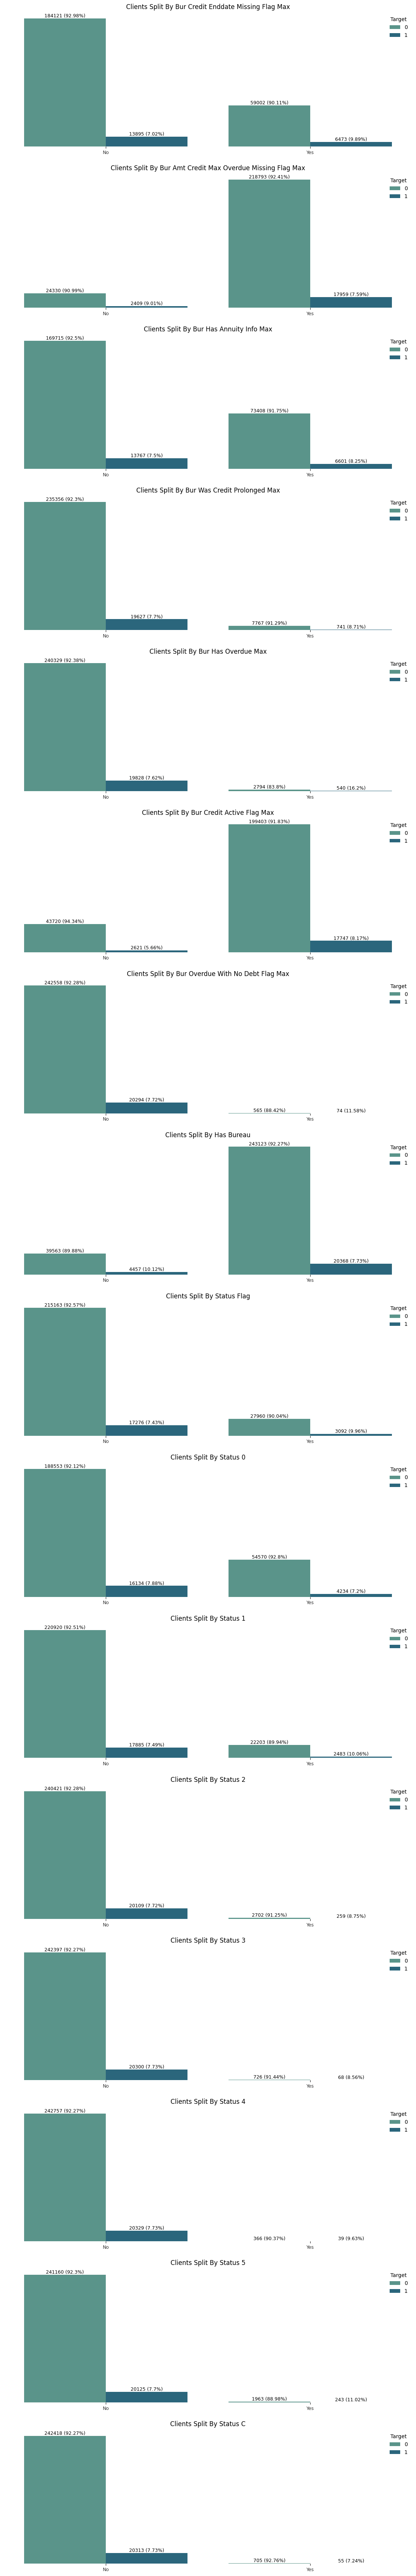

In [21]:
size = len(bi_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

palette = 'crest'

i = 0
for item in bi_f:
    temp = app_train_cleaned.groupby(item)['TARGET'].value_counts()

    title = item.replace("_", " ").title()

    ax = bar_plot_multi_index_f(temp, item, 'TARGET', f'Clients Split By {title}', palette, ax=axs[i])

    ax.legend(edgecolor='none', title='Target')
    ax.set_xticklabels(['No', 'Yes'])

    i += 1

Binary features in the bureau dataset are unbalanced, with some features being much rarer than others. Despite this, certain tendencies can be observed that increase the likelihood of repayment problems. For example, clients with a missing credit end date flag are more likely to have the target outcome (9.89%) compared to those without the flag (7.02%).

### Non-Binary Features



In [22]:
size = len(num_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

i = 0
for item in num_f:

    title = item.replace("_", " ").title()
    ax01 = simple_kdeplot(app_train_cleaned, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i])

    i += 1

There are no clear tendencies observable with respect to the target. Many of the features are highly skewed, indicating non-normal distributions.

## POS Cash Balance

In [23]:
num_bi_f = pos_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if item in app_train_cleaned.columns:
        if len(app_train_cleaned[item].dropna().unique()) > 2:
            num_f.append(item)
        else:
            bi_f.append(item)
    else:
        continue

### Binary Features

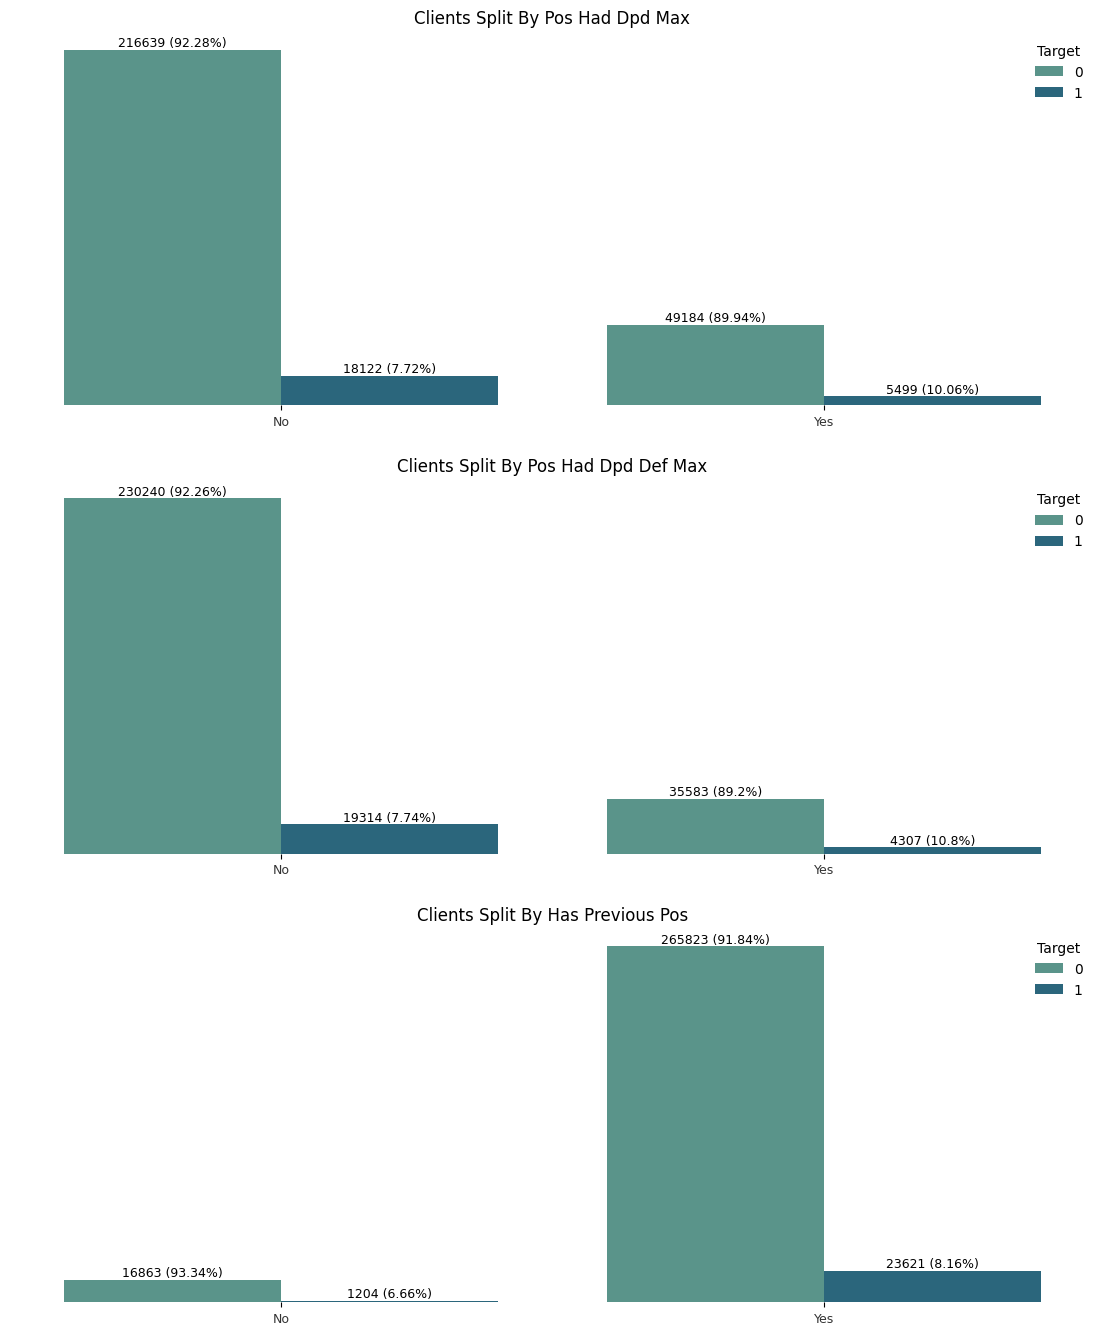

In [24]:
size = len(bi_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

i = 0
for item in bi_f:
    temp = app_train_cleaned.groupby(item)['TARGET'].value_counts()

    title = item.replace("_", " ").title()

    ax = bar_plot_multi_index_f(temp, item, 'TARGET', f'Clients Split By {title}', palette, ax=axs[i])

    ax.legend(edgecolor='none', title='Target')
    ax.set_xticklabels(['No', 'Yes'])

    i += 1

Binary features in the POS Cash Balance dataset are unbalanced, with some features being rarer than others. Despite this, certain tendencies can be observed that increase the likelihood of repayment problems. For example, clients who had DPD are more likely to have the target outcome (about 10%) compared to those without the flag (about 7.7%).

### Non-Binary Features

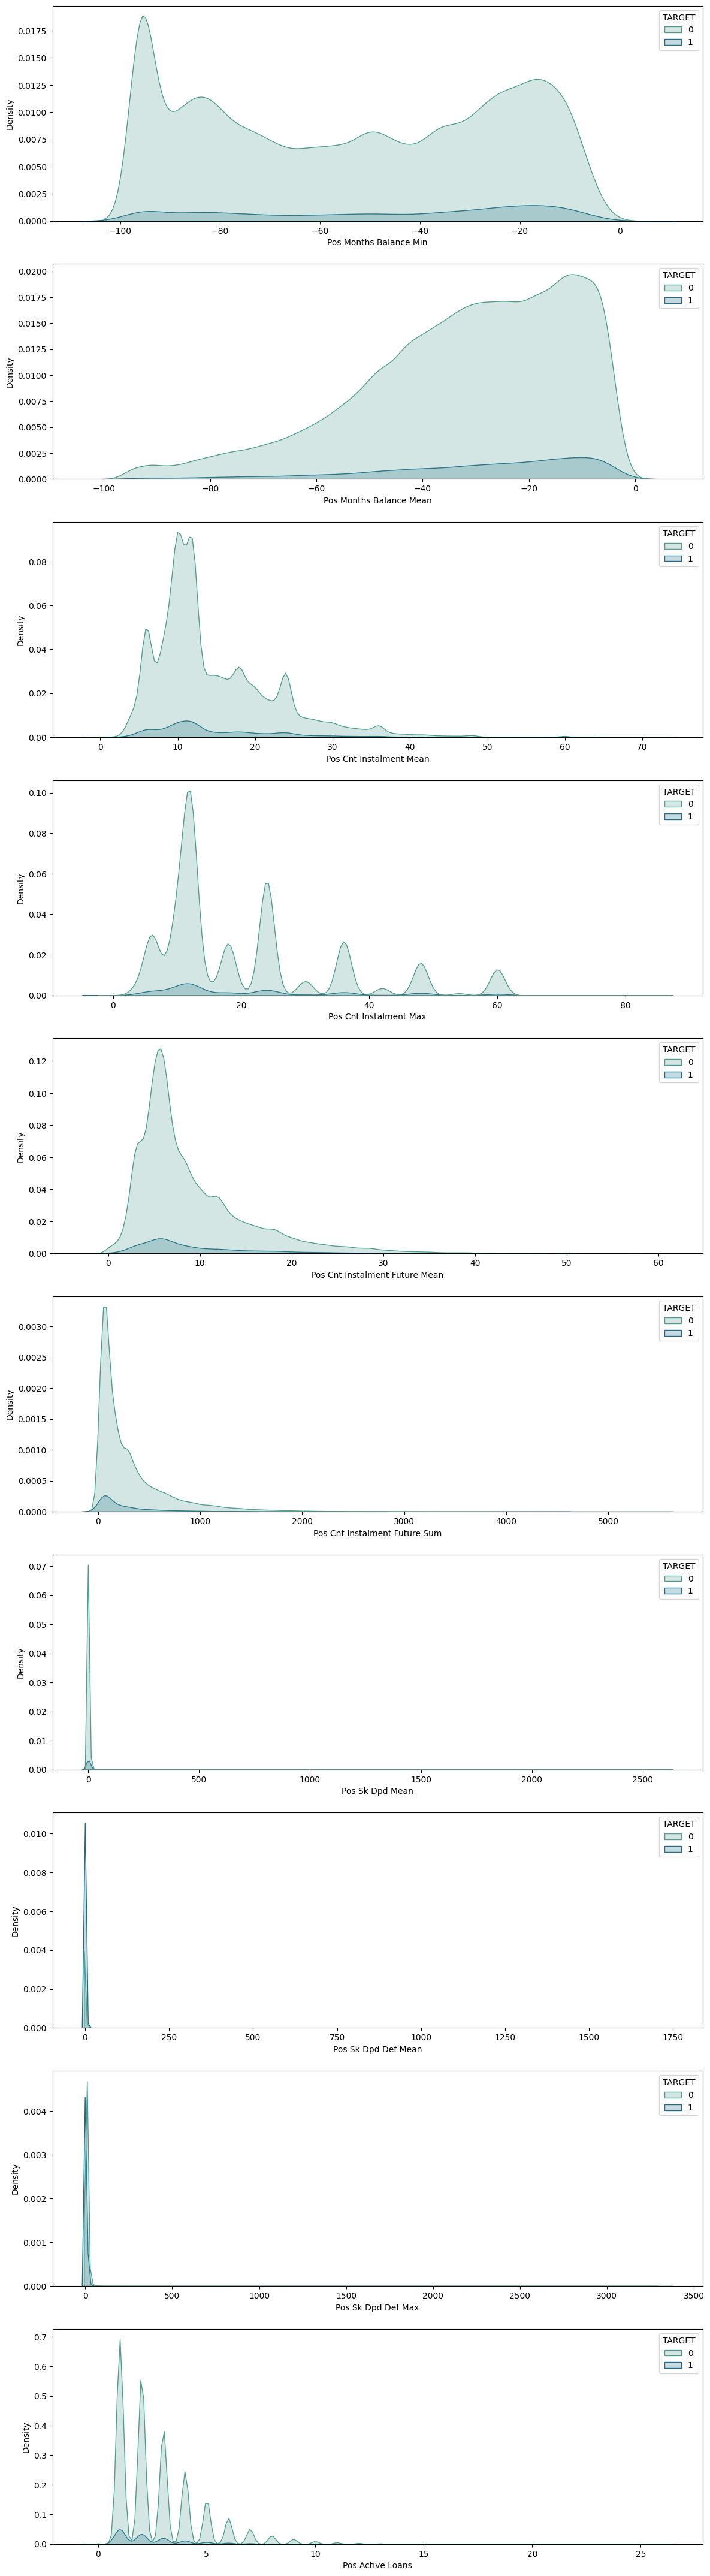

In [25]:
size = len(num_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

i = 0
for item in num_f:

    title = item.replace("_", " ").title()
    ax01 = simple_kdeplot(app_train_cleaned, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i])

    i += 1

There are no clear tendencies observable with respect to the target. Many of the features are highly skewed, indicating non-normal distributions.

## Credit Card Balance

In [26]:
num_bi_f = cc_bal_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if item in app_train_cleaned.columns:
        if len(app_train_cleaned[item].dropna().unique()) > 2:
            num_f.append(item)
        else:
            bi_f.append(item)
    else:
        continue

### Binary Features

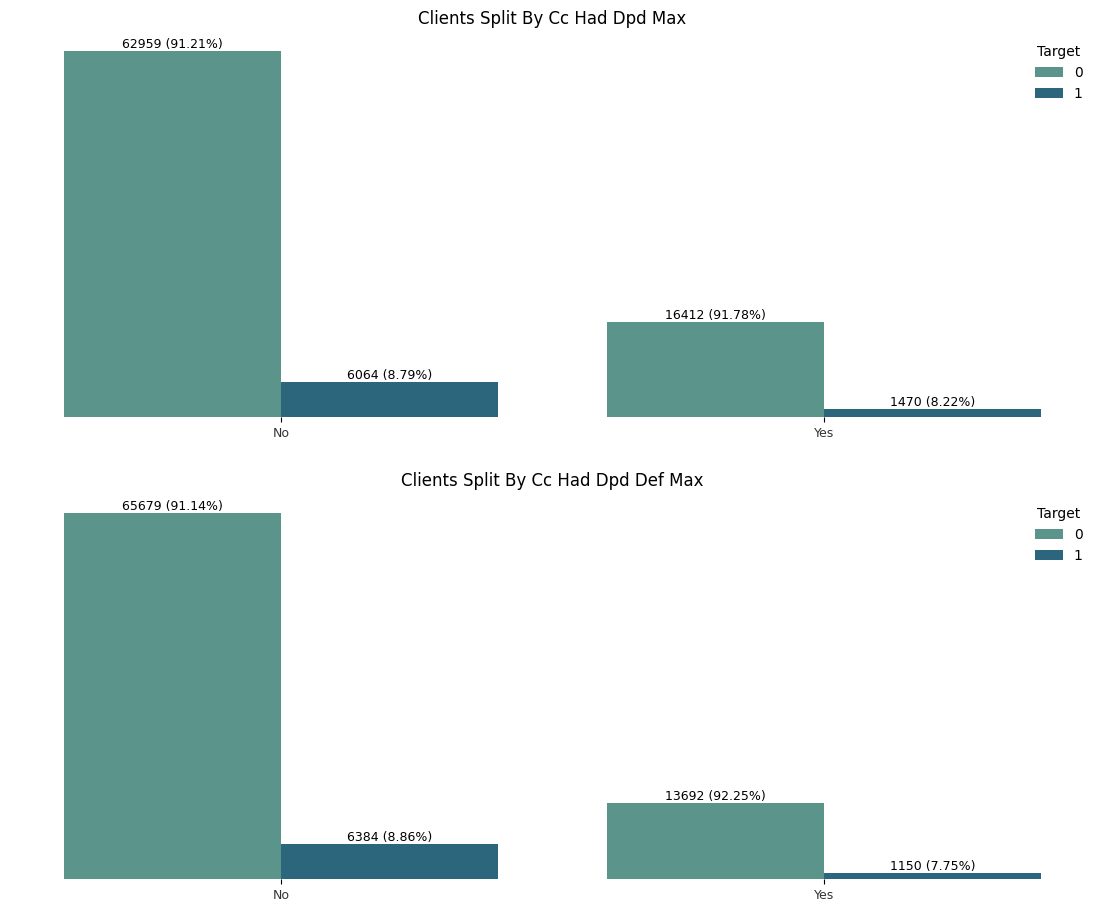

In [27]:
size = len(bi_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

i = 0
for item in bi_f:
    temp = app_train_cleaned.groupby(item)['TARGET'].value_counts()

    title = item.replace("_", " ").title()

    ax = bar_plot_multi_index_f(temp, item, 'TARGET', f'Clients Split By {title}', palette, ax=axs[i])

    ax.legend(edgecolor='none', title='Target')
    ax.set_xticklabels(['No', 'Yes'])

    i += 1

Binary features in the Credit card dataset are unbalanced, with some features being rarer than others. There are some minor tendencies which can be observed that increase the likelihood of repayment problems. Clients who had DPD are slightly less likely to have the target outcome (about 8%) compared to those without the flag (about 9%).

### Non-Binary Features

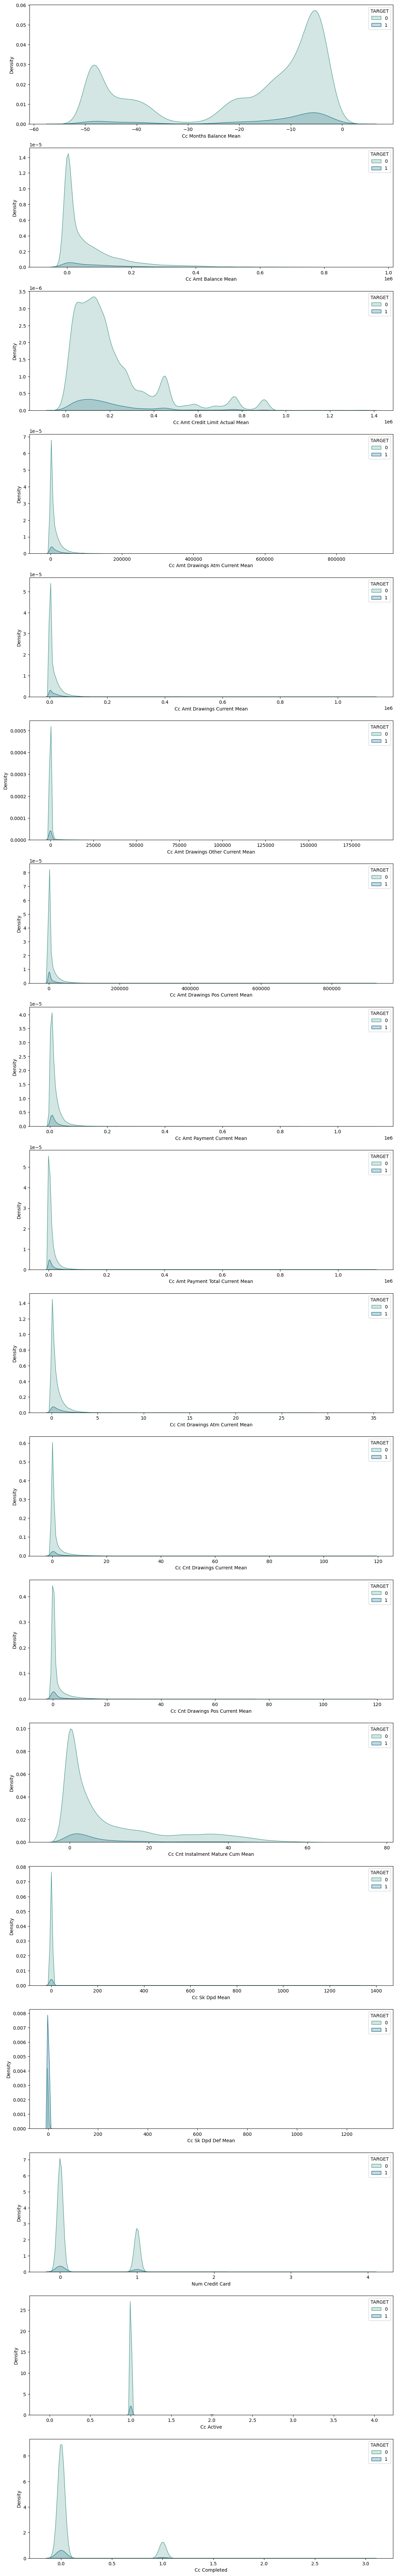

In [28]:
size = len(num_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

i = 0
for item in num_f:

    title = item.replace("_", " ").title()
    ax01 = simple_kdeplot(app_train_cleaned, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i])

    i += 1

There are no clear tendencies observable with respect to the target. Many of the features are highly skewed, indicating non-normal distributions.

## Previous Application

In [29]:
num_bi_f = prev_app_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if item in app_train_cleaned.columns:
        if len(app_train_cleaned[item].dropna().unique()) > 2:
            num_f.append(item)
        else:
            bi_f.append(item)
    else:
        continue

### Binary Features

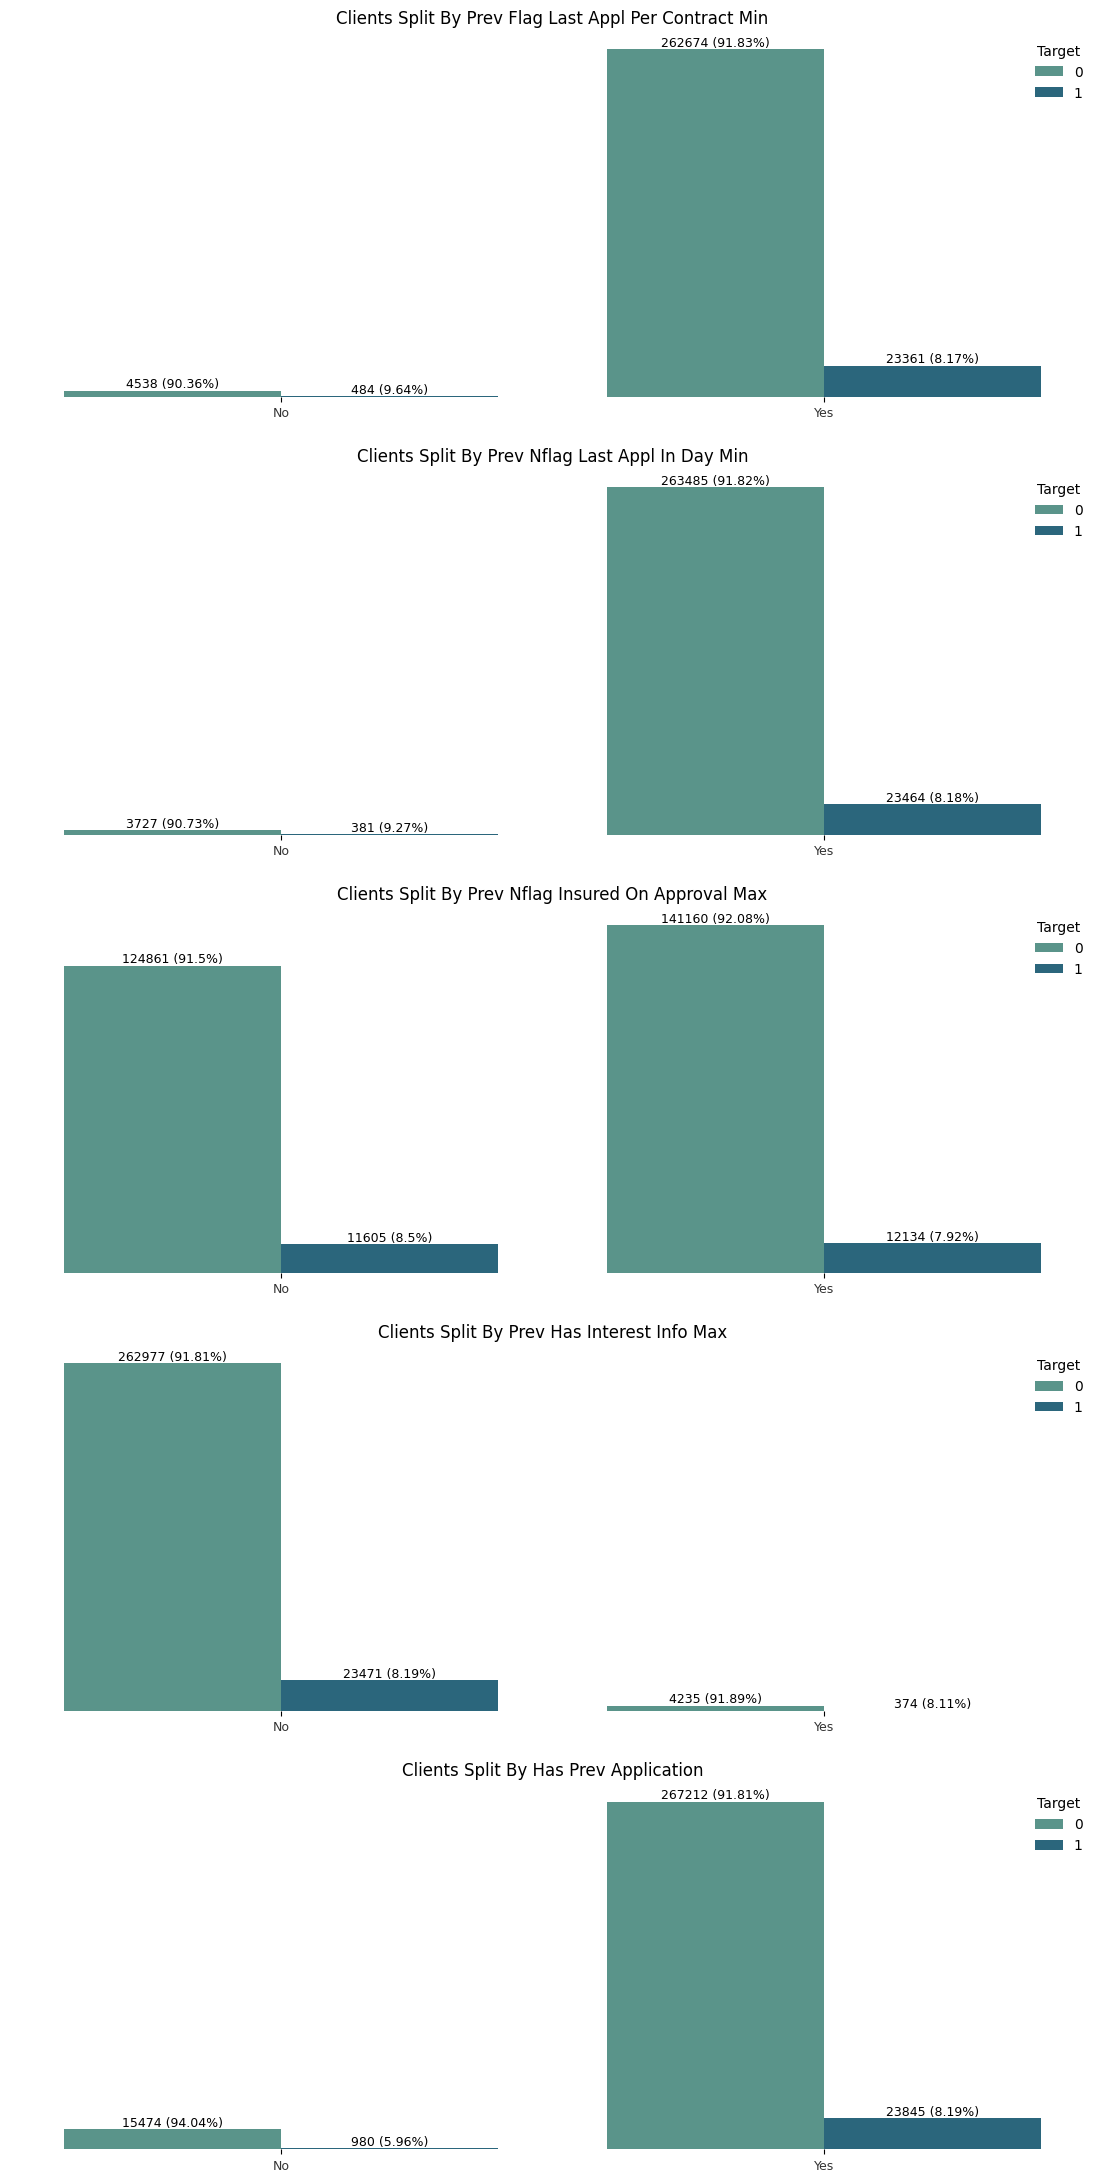

In [30]:
size = len(bi_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

i = 0
for item in bi_f:
    temp = app_train_cleaned.groupby(item)['TARGET'].value_counts()

    title = item.replace("_", " ").title()

    ax = bar_plot_multi_index_f(temp, item, 'TARGET', f'Clients Split By {title}', palette, ax=axs[i])

    ax.legend(edgecolor='none', title='Target')
    ax.set_xticklabels(['No', 'Yes'])

    i += 1

Binary features in the POS Cash Balance dataset are unbalanced, with some features being much rarer than others. Despite this, certain tendencies can be observed that increase the likelihood of repayment problems. For example, clients who had previous application are more likely to have the target outcome (8.19%) compared to those who didn't (about 5.96%).

### Non-Binary Features



In [31]:
size = len(num_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

i = 0
for item in num_f:

    title = item.replace("_", " ").title()
    ax01 = simple_kdeplot(app_train_cleaned, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i])

    i += 1

There are no clear tendencies observable with respect to the target. Many of the features are highly skewed, indicating non-normal distributions.

## Instalments Payments

In [32]:
num_bi_f = inst_pay_agg.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if item in app_train_cleaned.columns:
        if len(app_train_cleaned[item].dropna().unique()) > 2:
            num_f.append(item)
        else:
            bi_f.append(item)
    else:
        continue

bi_f

['HAD_INSTALMENT_PAYMENTS']

### Binary Features

[Text(0, 0, 'No'), Text(1, 0, 'Yes')]

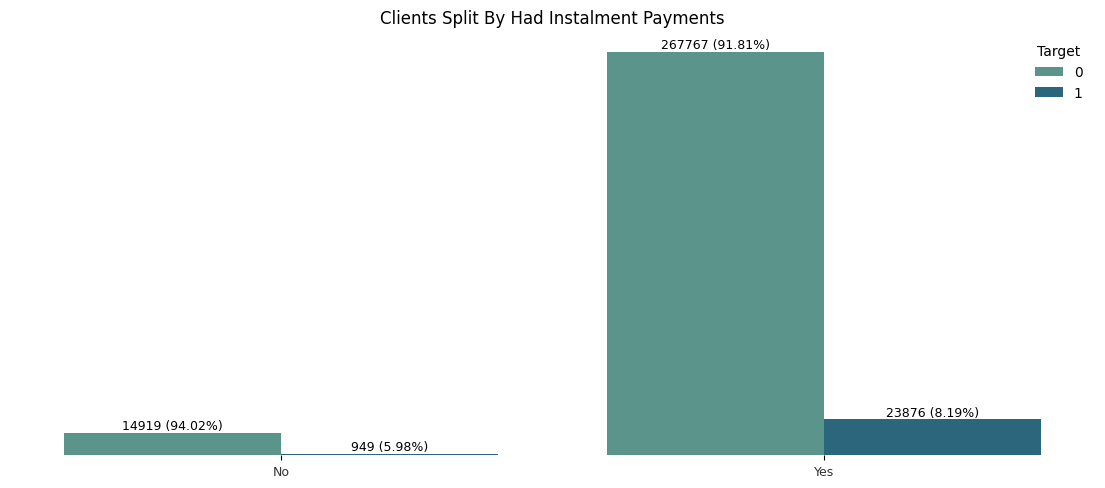

In [33]:
fig = plt.figure(figsize=(14, 5.5))

temp = app_train_cleaned.groupby(item)['TARGET'].value_counts()

title = item.replace("_", " ").title()

ax = bar_plot_multi_index_f(temp, bi_f, 'TARGET', f'Clients Split By {title}', palette)

ax.legend(edgecolor='none', title='Target')
ax.set_xticklabels(['No', 'Yes'])

Binary feature in the intalments payments dataset is unbalanced, with clients who didn't have instalment payments being much rarer. However, we can see that there is a tendency for people who were in the dataset to have increased likelihood of repayment problems. Clients who were in instalment payments dataset are more likely to have the target outcome (8.19%) compared to those who weren't (about 5.98%).

### Non-Binary Features

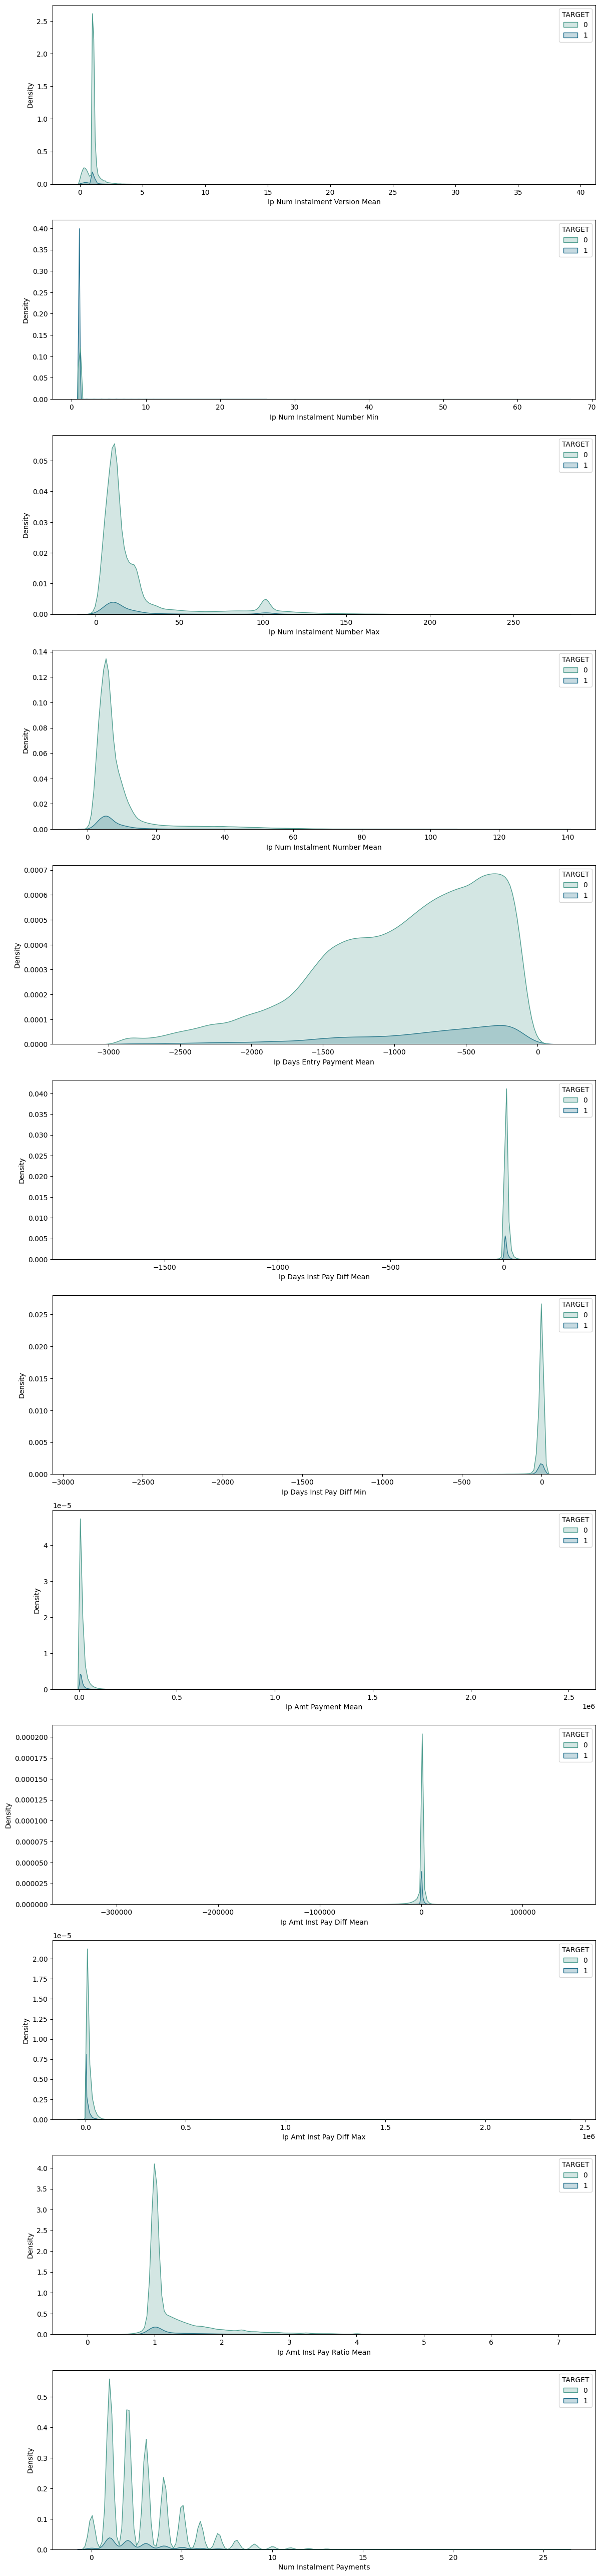

In [34]:
size = len(num_f)
fig, axs = plt.subplots(size, 1, figsize=(14, (5.5 * size)))

i = 0
for item in num_f:

    title = item.replace("_", " ").title()
    ax01 = simple_kdeplot(app_train_cleaned, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i])

    i += 1

There are no clear tendencies observable with respect to the target. Many of the features are highly skewed, indicating non-normal distributions.

# Perform Statistical Inference

In [35]:
num_bi_f = app_train_cleaned.iloc[:, 1:].select_dtypes(include=['float', 'int']).columns
num_f = []
bi_f = []

for item in num_bi_f:
    if len(app_train_cleaned[item].dropna().unique()) > 2:
        num_f.append(item)
    else:
        bi_f.append(item)
bi_f.remove("TARGET")

$ H_0 $ will always be that there is no difference, and $ H_1 $ accordingly will be that there is a difference. Chosen significance level – $ α $ will be 5% (or 0.05). Since there are a lot of features Bonferroni Correction will be used: $ α $ is going to be divided by the number of hypotheses made.

The results will determine whether or not the feature is going to be taken for modeling, as there is limited computing power and a lot of features. All of features which will have p above 0.1 will be removed.

In [36]:
cut = 0.1

In [37]:
total_tests = len(num_bi_f)
alfa = 0.05 / total_tests
print(f'Due to Bonferroni Correction significance level will be {alfa}')

Due to Bonferroni Correction significance level will be 0.00012437810945273634


## Binary Data Chi-Squared Test

Chi-square test is going to be used to check if there is a statistical difference in binary features.

### Application Train

#### Expanded Results

In [38]:
binary_list = []
significant = {}
not_significant = {}
cols = app_train_enc.columns
for item in cols:
    if item in bi_f:
        binary_list.append(item)

for i in binary_list:
    print(f'🔹 Feature: {i} \n')
    result = chi2_test_f(app_train_enc, 'TARGET', i, p=alfa)
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: FLAG_OWN_CAR 

FLAG_OWN_CAR      No    Yes
TARGET                     
No            185675  97011
Yes            17249   7576
Chi2ContingencyResult(statistic=np.float64(146.65601825576024), pvalue=np.float64(9.330994431109667e-34), dof=1, expected_freq=array([[186542.18504054,  96143.81495946],
       [ 16381.81495946,   8443.18504054]]))

Set p value is 0.00012437810945273634.
Results are statistically significant

--------------------------------------------------------------------
🔹 Feature: FLAG_OWN_REALTY 

FLAG_OWN_REALTY     No     Yes
TARGET                        
No               86357  196329
Yes               7842   16983
Chi2ContingencyResult(statistic=np.float64(11.575827298084178), pvalue=np.float64(0.0006681470317545887), dof=1, expected_freq=array([[ 86594.42593598, 196091.57406402],
       [  7604.57406402,  17220.42593598]]))

Set p value is 0.00012437810945273634.
Results are not statistically significant

------------------------------------------------

#### Results 

In [39]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
OCCUPATION_TYPE_GROUPED_Manual,8.525526e-300
NAME_INCOME_TYPE_Working,7.225960e-223
NAME_EDUCATION_TYPE_Higher education,4.439836e-216
CODE_GENDER_M,4.183493e-202
NAME_EDUCATION_TYPE_SECONDARY,1.490964e-192
REG_CITY_NOT_WORK_CITY,7.981277e-176
NAME_EDUCATION_TYPE_Secondary / secondary special,6.091193e-168
OCCUPATION_TYPE_Not employed,2.513138e-143
REG_CITY_NOT_LIVE_CITY,1.075235e-133
FLAG_DOCUMENT_3,1.855748e-133


In [40]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
REG_REGION_NOT_WORK_REGION,0.000126
WALLSMATERIAL_MODE_Block,0.000185
FLAG_DOCUMENT_15,0.000417
ORGANIZATION_TYPE_Industry: type 1,0.000477
FLAG_OWN_REALTY,0.000668
ORGANIZATION_TYPE_Transport: type 4,0.001104
ORGANIZATION_TYPE_Kindergarten,0.001503
ORGANIZATION_TYPE_Trade: type 6,0.001711
REG_REGION_NOT_LIVE_REGION,0.002177
ORGANIZATION_TYPE_Industry: type 9,0.003170


Many categorical features show extremely strong statistical associations with the target variable (p-values close to 0).
- The most significant predictors include occupation type, income type, education level, gender, and city mismatch features. These suggest that socio-demographic and employment-related characteristics play a major role in default risk.
- Features related to documentation (e.g., FLAG_DOCUMENT_3, FLAG_WORK_PHONE, etc.) and housing type also show notable associations.
- A large group of organizational types and industry categories also have statistically significant but relatively weaker associations compared to the top features.

Features such as application weekday, some organizational types, rare housing types, and some document flags show no strong statistical relationship with repayment difficulties.
- For example, WEEKDAY_APPR_PROCESS_START (Monday–Sunday) and FLAG_EMAIL have p-values well above conventional thresholds (0.05+), indicating they do not meaningfully differentiate between good and bad borrowers.
- Certain rare categories like terraced house, office apartments, or very specific industries (e.g., Industry: type 8, Religion, Postal, Mobile) also show very weak association with the target.
- This suggests that these features are either uninformative or too sparse to be reliable predictors.

In [41]:
mask = df_not_significant > cut

list_to_drop = df_not_significant[mask].dropna().index
list_to_drop

Index(['ORGANIZATION_TYPE_Electricity', 'LIVE_REGION_NOT_WORK_REGION',
       'NAME_EDUCATION_TYPE_Incomplete higher', 'NAME_TYPE_SUITE_Children',
       'ORGANIZATION_TYPE_Industry: type 13', 'OCCUPATION_TYPE_HR staff',
       'WEEKDAY_APPR_PROCESS_START_SATURDAY', 'OCCUPATION_TYPE_Secretaries',
       'OCCUPATION_TYPE_IT staff', 'ORGANIZATION_TYPE_Trade: type 4',
       'ORGANIZATION_TYPE_Industry: type 11',
       'ORGANIZATION_TYPE_Industry: type 5', 'FLAG_EMAIL', 'CAR_AGE_WAS_64',
       'WALLSMATERIAL_MODE_Mixed', 'WEEKDAY_APPR_PROCESS_START_WEDNESDAY',
       'NAME_TYPE_SUITE_Spouse, partner', 'ORGANIZATION_TYPE_Emergency',
       'WEEKDAY_APPR_PROCESS_START_SUNDAY',
       'WEEKDAY_APPR_PROCESS_START_FRIDAY', 'NAME_FAMILY_STATUS_Separated',
       'FLAG_DOCUMENT_19', 'ORGANIZATION_TYPE_Mobile',
       'ORGANIZATION_TYPE_Industry: type 2', 'ORGANIZATION_TYPE_Postal',
       'ORGANIZATION_TYPE_Religion', 'HOUSETYPE_MODE_terraced house',
       'ORGANIZATION_TYPE_Trade: type 1',
 

In [42]:
app_train_cleaned = app_train_cleaned.drop(columns=list_to_drop)

### Bureau

#### Expanded Results

In [43]:
binary_list = []
significant = {}
not_significant = {}
cols = bureau_agg.columns
for item in cols:
    if item in bi_f:
        binary_list.append(item)

for i in binary_list:
    print(f'🔹 Feature: {i} \n')
    result = chi2_test_f(app_train_cleaned, 'TARGET', i, p=alfa)
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: BUR_CREDIT_ENDDATE_MISSING_FLAG_MAX 

BUR_CREDIT_ENDDATE_MISSING_FLAG_MAX      No    Yes
TARGET                                            
No                                   184121  59002
Yes                                   13895   6473
Chi2ContingencyResult(statistic=np.float64(567.482879576387), pvalue=np.float64(1.9808889761105746e-125), dof=1, expected_freq=array([[182709.25370506,  60413.74629494],
       [ 15306.74629494,   5061.25370506]]))

Set p value is 0.00012437810945273634.
Results are statistically significant

--------------------------------------------------------------------
🔹 Feature: BUR_AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG_MAX 

BUR_AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG_MAX     No     Yes
TARGET                                                    
No                                           24330  218793
Yes                                           2409   17959
Chi2ContingencyResult(statistic=np.float64(68.0799808550972), pvalue=np.float64(1.569965162

#### Results 

In [44]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
BUR_CREDIT_ENDDATE_MISSING_FLAG_MAX,1.980889e-125
BUR_CREDIT_ACTIVE_FLAG_MAX,1.157315e-75
BUR_HAS_OVERDUE_MAX,1.593088e-75
HAS_BUREAU,2.740698e-65
STATUS_FLAG,4.099350e-55
STATUS_1,7.377429e-47
BUR_AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG_MAX,1.569965e-16
BUR_HAS_ANNUITY_INFO_MAX,4.242440e-11
STATUS_5,8.305917e-09
STATUS_0,5.040224e-08


In [45]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
BUR_OVERDUE_WITH_NO_DEBT_FLAG_MAX,0.000350
BUR_WAS_CREDIT_PROLONGED_MAX,0.000631
STATUS_2,0.040437
STATUS_4,0.180439
STATUS_3,0.415120
STATUS_C,0.658600


There are features, which show extremely strong statistical associations, for example:
- There is a statistical difference for applicants with missing credit end dates in bureau records. 
- BUR_CREDIT_ACTIVE_FLAG and BUR_HAS_OVERDUE are also among the strongest predictors. 
- HAS_BUREAU - simply having bureau data is predictive, as clients with no bureau history are systematically different from those with credit history.

Several features show little or no association with repayment behavior:
- STATUS_3, STATUS_4, STATUS_C (p = 0.18 – 0.66). These higher-risk repayment states occur too infrequently or inconsistently to provide strong predictive value.

In [46]:
mask = df_not_significant > cut

list_to_drop = df_not_significant[mask].dropna().index
list_to_drop

Index(['STATUS_4', 'STATUS_3', 'STATUS_C'], dtype='object')

In [47]:
app_train_cleaned = app_train_cleaned.drop(columns=list_to_drop)

### POS Cash Balance

#### Expanded Results

In [48]:
binary_list = []
significant = {}
not_significant = {}
cols = pos_agg.columns
for item in cols:
    if item in bi_f:
        binary_list.append(item)

for i in binary_list:
    print(f'🔹 Feature: {i} \n')
    result = chi2_test_f(app_train_cleaned, 'TARGET', i, p=alfa)
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: POS_HAD_DPD_MAX 

POS_HAD_DPD_MAX      No    Yes
TARGET                        
No               216639  49184
Yes               18122   5499
Chi2ContingencyResult(statistic=np.float64(322.83199756743585), pvalue=np.float64(3.499767625211151e-72), dof=1, expected_freq=array([[215602.58047498,  50220.41952502],
       [ 19158.41952502,   4462.58047498]]))

Set p value is 0.00012437810945273634.
Results are statistically significant

--------------------------------------------------------------------
🔹 Feature: POS_HAD_DPD_DEF_MAX 

POS_HAD_DPD_DEF_MAX      No    Yes
TARGET                            
No                   230240  35583
Yes                   19314   4307
Chi2ContingencyResult(statistic=np.float64(428.6503345773591), pvalue=np.float64(3.1962715297243045e-95), dof=1, expected_freq=array([[229188.35056868,  36634.64943132],
       [ 20365.64943132,   3255.35056868]]))

Set p value is 0.00012437810945273634.
Results are statistically significant

-----------------

#### Results 

In [49]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
POS_HAD_DPD_DEF_MAX,3.196272e-95
POS_HAD_DPD_MAX,3.499768e-72
HAS_PREVIOUS_POS,8.632384e-13


In [50]:
not_significant

{}

POS_HAD_DPD_DEF_MAX, POS_HAD_DPD_MAX and HAS_PREVIOUS_POS are all statistically significant.

Most powerful POS predictors:
- POS_HAD_DPD_DEF_MAX 
- POS_HAD_DPD_MAX

Secondary predictor:
- HAS_PREVIOUS_POS (loan history presence)

Practical Implication: POS delinquency history is a high-value variable for credit risk scoring.

### Credit Card Balance

#### Expanded Results

In [51]:
binary_list = []
significant = {}
not_significant = {}
cols = cc_bal_agg.columns
for item in cols:
    if item in bi_f:
        binary_list.append(item)

for i in binary_list:
    print(f'🔹 Feature: {i} \n')
    result = chi2_test_f(app_train_cleaned, 'TARGET', i, p=alfa)
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: CC_HAD_DPD_MAX 

CC_HAD_DPD_MAX     No    Yes
TARGET                      
No              62959  16412
Yes              6064   1470
Chi2ContingencyResult(statistic=np.float64(5.653426493927501), pvalue=np.float64(0.017421298712896396), dof=1, expected_freq=array([[63039.23287498, 16331.76712502],
       [ 5983.76712502,  1550.23287498]]))

Set p value is 0.00012437810945273634.
Results are not statistically significant

--------------------------------------------------------------------
🔹 Feature: CC_HAD_DPD_DEF_MAX 

CC_HAD_DPD_DEF_MAX     No    Yes
TARGET                          
No                  65679  13692
Yes                  6384   1150
Chi2ContingencyResult(statistic=np.float64(19.033571280450868), pvalue=np.float64(1.2843878064481315e-05), dof=1, expected_freq=array([[65815.68808469, 13555.31191531],
       [ 6247.31191531,  1286.68808469]]))

Set p value is 0.00012437810945273634.
Results are statistically significant

----------------------------------------

#### Results 

In [52]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
CC_HAD_DPD_DEF_MAX,0.000013


In [53]:
not_significant

{'CC_HAD_DPD_MAX': np.float64(0.017421298712896396)}

CC_HAD_DPD_DEF_MAX is statistically significant. CC_HAD_DPD_MAX also has a low p value, however due to limits set by Bonferroni Correction significance level, the result is not considered to be statistically significant.

### Previous Application

#### Expanded Results

In [54]:
binary_list = []
significant = {}
not_significant = {}
cols = prev_app_agg.columns
for item in cols:
    if item in bi_f:
        binary_list.append(item)

for i in binary_list:
    print(f'🔹 Feature: {i} \n')
    result = chi2_test_f(app_train_cleaned, 'TARGET', i, p=alfa)
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: PREV_FLAG_LAST_APPL_PER_CONTRACT_MIN 

PREV_FLAG_LAST_APPL_PER_CONTRACT_MIN    No     Yes
TARGET                                            
No                                    4538  262674
Yes                                    484   23361
Chi2ContingencyResult(statistic=np.float64(13.992446915236782), pvalue=np.float64(0.00018354648075828093), dof=1, expected_freq=array([[  4610.56997083, 262601.43002917],
       [   411.43002917,  23433.56997083]]))

Set p value is 0.00012437810945273634.
Results are not statistically significant

--------------------------------------------------------------------
🔹 Feature: PREV_NFLAG_LAST_APPL_IN_DAY_MIN 

PREV_NFLAG_LAST_APPL_IN_DAY_MIN    No     Yes
TARGET                                       
No                               3727  263485
Yes                               381   23464
Chi2ContingencyResult(statistic=np.float64(6.341057046699176), pvalue=np.float64(0.011797455586991275), dof=1, expected_freq=array([[  3771.44990844,

#### Results 

In [55]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
HAS_PREV_APPLICATION,1.441680e-24
PREV_NFLAG_INSURED_ON_APPROVAL_MAX,8.495186e-09


In [56]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
PREV_FLAG_LAST_APPL_PER_CONTRACT_MIN,0.000184
PREV_NFLAG_LAST_APPL_IN_DAY_MIN,0.011797
PREV_HAS_INTEREST_INFO_MAX,0.866937


- HAS_PREV_APPLICATION: there is a statistical difference between clients who have applied previously and those who hasn't.
- PREV_NFLAG_INSURED_ON_APPROVAL_MAX: also has a statistical difference. Whether the previous application had some form of insurance flag at approval.
- PREV_HAS_INTEREST_INFO_MAX: no statistical difference. Suggests that interest-related flags from previous applications add little predictive value.

In [57]:
mask = df_not_significant > cut

list_to_drop = df_not_significant[mask].dropna().index
list_to_drop

Index(['PREV_HAS_INTEREST_INFO_MAX'], dtype='object')

In [58]:
app_train_cleaned = app_train_cleaned.drop(columns=list_to_drop)

### Installments Payments

#### Expanded Results

In [59]:
binary_list = []
significant = {}
not_significant = {}
cols = inst_pay_agg.columns
for item in cols:
    if item in bi_f:
        binary_list.append(item)

for i in binary_list:
    print(f'🔹 Feature: {i} \n')
    result = chi2_test_f(app_train_cleaned, 'TARGET', i, p=alfa)
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: HAD_INSTALMENT_PAYMENTS 

HAD_INSTALMENT_PAYMENTS     No     Yes
TARGET                                
No                       14919  267767
Yes                        949   23876
Chi2ContingencyResult(statistic=np.float64(98.39988324173237), pvalue=np.float64(3.418793997812221e-23), dof=1, expected_freq=array([[ 14586.99509286, 268099.00490714],
       [  1281.00490714,  23543.99509286]]))

Set p value is 0.00012437810945273634.
Results are statistically significant

--------------------------------------------------------------------


#### Results

In [60]:
significant

{'HAD_INSTALMENT_PAYMENTS': np.float64(3.418793997812221e-23)}

In [61]:
not_significant

{}

Information that a client had instalment payments is statistically significant.

## Non-Binary Numerical Data

Numerical variables will be tested for normality using the Kolmogorov–Smirnov (KS) test. This step ensures that we choose the most appropriate statistical method for comparing distributions between groups.

- If the KS test indicates that the data follows a normal distribution, a t-test will be applied.
- If the data significantly deviates from normality, the Mann–Whitney U test (a non-parametric alternative) will be used instead.

This approach ensures that statistical comparisons are both robust and reliable, minimizing the risk of drawing misleading conclusions from incorrect test assumptions.

In [62]:
mask = app_train_cleaned['TARGET'] == 1

target = app_train_cleaned[mask]
no_target = app_train_cleaned[~mask]

assert len(target) + len(no_target) == len(app_train_cleaned)

### Application train

In [63]:
num_list = []
cols = app_train_enc.columns
for item in cols:
    if item in num_f:
        num_list.append(item)

#### Checking for Normality

In [64]:
normal = []
n_normal = []
for i in num_list:
    print(f'🔹 Feature: {i} \n')
    result = analyze_distribution(app_train_cleaned, i)
    if result:
        normal.append(i)
    else:
        n_normal.append(i)
    print('--------------------------------------------------------------------')

🔹 Feature: CNT_CHILDREN 

Skewness: 1.933
Kurtosis: 6.334

📈 Kolmogorov-Smirnov Test:
Statistic: 0.419, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: AMT_INCOME_TOTAL 

Skewness: 4.276
Kurtosis: 56.605

📈 Kolmogorov-Smirnov Test:
Statistic: 0.153, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: AMT_CREDIT 

Skewness: 1.252
Kurtosis: 2.012

📈 Kolmogorov-Smirnov Test:
Statistic: 0.110, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: AMT_ANNUITY 

Skewness: 1.608
Kurtosis: 8.533

📈 Kolmogorov-Smirnov Test:
Statistic: 0.078, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: AMT_GOODS_PRICE 

Skewness: 1.362
Kurtosis: 2.493

📈 Kolmogorov-Smirnov Test:
Statistic: 0.143, p-value: 0.000
→ Likely not normal
------------------------

In [65]:
len(normal)

0

#### Expanded Results

In [66]:
significant = {}
not_significant = {}
for i in n_normal:
    print(f'🔹 Feature: {i}')
    result = hypothesis_tests_f(
        target[i].dropna(),
        no_target[i].dropna(),
        p=alfa,
        name_x='Target',
        name_y='No Target',
        test=['mw'],
    )
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: CNT_CHILDREN
95% confidence intervals:

Target
(np.float64(0.4543906784864558), np.float64(0.4732226145649037))
No Target
(np.float64(0.4102958993664393), np.float64(0.415595725970507))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(3629005634.5), pvalue=np.float64(8.763849498390257e-29))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: AMT_INCOME_TOTAL
95% confidence intervals:

Target
(np.float64(159818.61020317118), np.float64(161990.7847213001))
No Target
(np.float64(168670.46691678808), np.float64(169484.9776148477))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(3374388895.0), pvalue=np.float64(9.203815897326016e-24))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: AMT_CRED

#### Results

In [67]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
EXT_SOURCE_3,0.000000e+00
EXT_SOURCE_1,0.000000e+00
EXT_SOURCE_2,0.000000e+00
AGE_YEARS,0.000000e+00
YEARS_EMPLOYED,0.000000e+00
GOODS_CREDIT_RATIO,3.571319e-300
REGION_RATING_CLIENT_W_CITY,2.679860e-250
REGION_RATING_CLIENT,4.555792e-234
DAYS_ID_PUBLISH,1.391775e-186
DAYS_LAST_PHONE_CHANGE,7.186589e-175


In [68]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
AMT_REQ_CREDIT_BUREAU_MON,0.000376
AMT_REQ_CREDIT_BUREAU_DAY,0.011224
NONLIVINGAPARTMENTS_AVG,0.053312
NONLIVINGAPARTMENTS_MEDI,0.121274
NONLIVINGAPARTMENTS_MODE,0.261002
CREDIT_INCOME_RATIO,0.324804
AMT_REQ_CREDIT_BUREAU_HOUR,0.609111
AMT_REQ_CREDIT_BUREAU_WEEK,0.704276
AMT_ANNUITY,0.967562


To evaluate differences in numerical features between clients with and without repayment difficulties, the Mann–Whitney U test was applied. This test is suitable here because many variables do not follow a normal distribution (as shown by KS test results).

**Features with Strongest Discriminative Power (lowest p-values)** – the following features show extremely strong statistical significance, suggesting they are highly discriminative for predicting default risk:
- External risk sources (EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3) – all with p-values ≈ 0, confirming they are among the strongest predictors.
- Demographics and history: Age, Years Employed, Days of ID Publication, Registration, and Last Phone Change.
- Credit-related ratios: Goods/Credit Ratio, Annuity/Credit Ratio, and Annuity/Income Ratio.
- Housing and living conditions: Region ratings, living area size, total area, apartment and floor information, number of children, and building condition variables (e.g., missing building information).

These features have extremely low p-values (often below 1e-50), indicating very strong separation between the two groups (repayers vs. defaulters).

**Features with Weakest Discriminative Power (highest p-values)** – some features showed little to no statistically significant difference between groups, making them less relevant for modeling:
- Credit bureau request counts (hourly, weekly, monthly, daily).
- Annuity amount (AMT_ANNUITY).
- Non-living area/apartment variables (NONLIVINGAPARTMENTS_, NONLIVINGAREA_).
- Credit/Income Ratio.

For example, AMT_ANNUITY has a p-value of 0.967, indicating no meaningful distinction between target groups. Similarly, AMT_REQ_CREDIT_BUREAU_HOUR and AMT_REQ_CREDIT_BUREAU_WEEK have very high p-values, suggesting these features provide little predictive signal.

In [69]:
mask = df_not_significant > cut

list_to_drop = df_not_significant[mask].dropna().index
list_to_drop

Index(['NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAPARTMENTS_MODE',
       'CREDIT_INCOME_RATIO', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_ANNUITY'],
      dtype='object')

In [70]:
app_train_cleaned = app_train_cleaned.drop(columns=list_to_drop)

### Bureau

In [71]:
num_list = []
cols = bureau_agg.columns
for item in cols:
    if item in num_f:
        num_list.append(item)

#### Checking for Normality

In [72]:
normal = []
n_normal = []
for i in num_list:
    print(f'🔹 Feature: {i} \n')
    result = analyze_distribution(app_train_cleaned, i)
    if result:
        normal.append(i)
    else:
        n_normal.append(i)
    print('--------------------------------------------------------------------')

🔹 Feature: BUR_DAYS_CREDIT_MEAN 

Skewness: -0.505
Kurtosis: 0.082

📈 Kolmogorov-Smirnov Test:
Statistic: 0.029, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: BUR_CREDIT_DAY_OVERDUE_MEAN 

Skewness: 52.329
Kurtosis: 3902.462

📈 Kolmogorov-Smirnov Test:
Statistic: 0.503, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: BUR_DAYS_CREDIT_ENDDATE_MEAN 

Skewness: 4.875
Kurtosis: 33.499

📈 Kolmogorov-Smirnov Test:
Statistic: 0.269, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: BUR_DAYS_ENDDATE_FACT_MIN 

Skewness: 0.084
Kurtosis: -1.247

📈 Kolmogorov-Smirnov Test:
Statistic: 0.086, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: BUR_DAYS_ENDDATE_FACT_MEAN 

Skewness: -0.573
Kurtosis: 0.128

📈 Kolmogorov-Smirnov Test:
Statisti

In [73]:
len(normal)

0

#### Expanded Results

In [74]:
significant = {}
not_significant = {}
for i in n_normal:
    print(f'🔹 Feature: {i}')
    result = hypothesis_tests_f(
        target[i].dropna(),
        no_target[i].dropna(),
        p=alfa,
        name_x='Target',
        name_y='No Target',
        test=['mw'],
    )
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: BUR_DAYS_CREDIT_MEAN
95% confidence intervals:

Target
(np.float64(-916.0578140112373), np.float64(-900.7662577359963))
No Target
(np.float64(-1099.9090715698057), np.float64(-1095.4457869327098))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(2986042246.5), pvalue=np.float64(0.0))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: BUR_CREDIT_DAY_OVERDUE_MEAN
95% confidence intervals:

Target
(np.float64(1.2217170198171141), np.float64(2.2987429440358413))
No Target
(np.float64(0.8783001678919221), np.float64(1.07205614583612))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(2512418125.0), pvalue=np.float64(1.3816399209416355e-71))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: BUR

#### Results

In [75]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
BUR_DAYS_CREDIT_MEAN,0.000000e+00
BUR_DAYS_CREDIT_UPDATE_MEAN,0.000000e+00
BUR_DEBT_CREDIT_RATIO_MEAN,0.000000e+00
BUR_DAYS_CREDIT_ENDDATE_MEAN,4.399949e-258
CREDIT_ACTIVE_ACTIVE,6.783827e-189
BUR_DAYS_ENDDATE_FACT_MEAN,4.743596e-167
BUR_AMT_CREDIT_SUM_DEBT_MEAN,2.456295e-163
BUR_DAYS_ENDDATE_FACT_MIN,2.570982e-157
BUR_MONTHS_BALANCE_MEAN,4.304906e-142
CREDIT_ACTIVE_CLOSED,3.513629e-114


In [76]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
BUR_CNT_CREDIT_PROLONG_MEAN,0.000629
NUM_CURRENCY_2,0.002545
NUM_CURRENCY_OTHER,0.005930
NUM_DISTINCT_CURRENCIES,0.006462
NUM_CURRENCY_3,0.250462


The Mann–Whitney U test was applied. It is suitable here because variables do not follow a normal distribution (as shown by KS test results).
The test highlights very strong signals of client risk coming from bureau information:

- Credit history timing is crucial
    - Features like Days since last credit (BUR_DAYS_CREDIT_MEAN), update dates, and end dates are highly significant. Clients with shorter and more recent credit histories are more likely to default.
- Debt ratios stand out
    - Debt-to-credit ratios and overdue-to-debt ratios are strong indicators. Higher debt burdens relative to available credit signal higher risk.
- Active vs. closed accounts matter
    - Having more active credits, especially consumer or credit card loans, is strongly linked with higher risk. In contrast, more closed credits reduce the likelihood of default.
- Loan type differentiation
    - Clients with active credit cards or consumer loans show higher risk, while mortgage loans are less risky. Car loans fall in the middle.
- Credit limits and sums
    - Both credit limits and amounts of credit/debt provide strong signals about repayment probability.

On the other hand, some bureau features have little to no predictive power:
- Credit prolongation counts and currency details (e.g., number of distinct currencies, secondary or unusual currencies) show much weaker or insignificant relationships with default.

Bureau data is powerful for risk assessment. The most valuable signals come from timing of credit activity, debt ratios, and type of active credit. In contrast, currency-based details and credit prolongation flags add little value and could be deprioritized in modeling.

In [77]:
mask = df_not_significant > cut

list_to_drop = df_not_significant[mask].dropna().index
list_to_drop

Index(['NUM_CURRENCY_3'], dtype='object')

In [78]:
app_train_cleaned = app_train_cleaned.drop(columns=list_to_drop)

### POS Cash Balance

In [79]:
num_list = []
cols = pos_agg.columns
for item in cols:
    if item in num_f:
        num_list.append(item)

#### Checking for Normality

In [80]:
normal = []
n_normal = []
for i in num_list:
    print(f'🔹 Feature: {i} \n')
    result = analyze_distribution(app_train_cleaned, i)
    if result:
        normal.append(i)
    else:
        n_normal.append(i)
    print('--------------------------------------------------------------------')

🔹 Feature: POS_MONTHS_BALANCE_MIN 

Skewness: -0.051
Kurtosis: -1.426

📈 Kolmogorov-Smirnov Test:
Statistic: 0.098, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: POS_MONTHS_BALANCE_MEAN 

Skewness: -0.798
Kurtosis: 0.143

📈 Kolmogorov-Smirnov Test:
Statistic: 0.075, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: POS_CNT_INSTALMENT_MEAN 

Skewness: 1.501
Kurtosis: 3.019

📈 Kolmogorov-Smirnov Test:
Statistic: 0.184, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: POS_CNT_INSTALMENT_MAX 

Skewness: 1.306
Kurtosis: 0.965

📈 Kolmogorov-Smirnov Test:
Statistic: 0.240, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: POS_CNT_INSTALMENT_FUTURE_MEAN 

Skewness: 1.906
Kurtosis: 5.043

📈 Kolmogorov-Smirnov Test:
Statistic: 0.155, p

In [81]:
len(normal)

0

#### Expanded Results

In [82]:
significant = {}
not_significant = {}
for i in n_normal:
    print(f'🔹 Feature: {i}')
    result = hypothesis_tests_f(
        target[i].dropna(),
        no_target[i].dropna(),
        p=alfa,
        name_x='Target',
        name_y='No Target',
        test=['mw'],
    )
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: POS_MONTHS_BALANCE_MIN
95% confidence intervals:

Target
(np.float64(-47.58136847450926), np.float64(-46.8376654359941))
No Target
(np.float64(-53.30405081814813), np.float64(-53.078993538435014))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(3506496729.5), pvalue=np.float64(1.3519007174730544e-195))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: POS_MONTHS_BALANCE_MEAN
95% confidence intervals:

Target
(np.float64(-29.760652139262515), np.float64(-29.24303391855123))
No Target
(np.float64(-32.11471878727895), np.float64(-31.9621005757243))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(3413897637.5), pvalue=np.float64(3.9775866464548256e-110))
Mann–Whitney U test results are statistically significant

----------------------------------------------------------------

#### Results

In [83]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
POS_MONTHS_BALANCE_MIN,1.351901e-195
POS_ACTIVE_LOANS,4.281053e-146
POS_MONTHS_BALANCE_MEAN,3.977587e-110
POS_SK_DPD_DEF_MEAN,2.258311e-109
POS_SK_DPD_DEF_MAX,1.045318e-102
POS_SK_DPD_MEAN,3.347506e-80
POS_CNT_INSTALMENT_FUTURE_MEAN,1.178019e-26
POS_CNT_INSTALMENT_FUTURE_SUM,1.770124e-22
POS_CNT_INSTALMENT_MEAN,7.962204e-17


In [84]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
POS_CNT_INSTALMENT_MAX,0.001135


Loan history timing is statistically significant:
- POS_MONTHS_BALANCE_MIN and MEAN (the earliest and average months of POS records) are significant.

Delinquency flags are predictive:
- Both POS_SK_DPD_DEF (defaulters days past due) and POS_SK_DPD (days past due in general) are among the strongest predictors.

Active loan presence matters
- POS_ACTIVE_LOANS is highly significant.

Future installments carry weight
- Features like POS_CNT_INSTALMENT_FUTURE (mean and sum) capture ongoing financial commitments.

Total installments are less important
- While POS_CNT_INSTALMENT_MEAN is statistically significant, the maximum number of installments (POS_CNT_INSTALMENT_MAX) has the weakest signal (p ≈ 0.001). This suggests that the volume of installments is less informative than payment behavior and delinquency patterns.

The most valuable predictors of default are delinquency patterns, active loan presence, and ongoing commitments. In contrast, simple installment counts add little incremental value and could be deprioritized.

### Credit Card Balance

In [85]:
num_list = []
cols = cc_bal_agg.columns
for item in cols:
    if item in num_f:
        num_list.append(item)

#### Checking for Normality

In [86]:
normal = []
n_normal = []
for i in num_list:
    print(f'🔹 Feature: {i} \n')
    result = analyze_distribution(app_train_cleaned, i)
    if result:
        normal.append(i)
    else:
        n_normal.append(i)
    print('--------------------------------------------------------------------')

🔹 Feature: CC_MONTHS_BALANCE_MEAN 

Skewness: -0.764
Kurtosis: -1.071

📈 Kolmogorov-Smirnov Test:
Statistic: 0.193, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: CC_AMT_BALANCE_MEAN 

Skewness: 2.596
Kurtosis: 8.730

📈 Kolmogorov-Smirnov Test:
Statistic: 0.256, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN 

Skewness: 1.807
Kurtosis: 3.223

📈 Kolmogorov-Smirnov Test:
Statistic: 0.183, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: CC_AMT_DRAWINGS_ATM_CURRENT_MEAN 

Skewness: 7.921
Kurtosis: 157.860

📈 Kolmogorov-Smirnov Test:
Statistic: 0.286, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: CC_AMT_DRAWINGS_CURRENT_MEAN 

Skewness: 7.167
Kurtosis: 128.266

📈 Kolmogorov-Smirnov Test:
Stat

In [87]:
len(normal)

0

#### Expanded Results

In [88]:
significant = {}
not_significant = {}
for i in n_normal:
    print(f'🔹 Feature: {i}')
    result = hypothesis_tests_f(
        target[i].dropna(),
        no_target[i].dropna(),
        p=alfa,
        name_x='Target',
        name_y='No Target',
        test=['mw'],
    )
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: CC_MONTHS_BALANCE_MEAN
95% confidence intervals:

Target
(np.float64(-16.485810547254193), np.float64(-15.799777265410887))
No Target
(np.float64(-19.96147855878826), np.float64(-19.726556134707653))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(336641053.5), pvalue=np.float64(3.148261876890184e-73))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: CC_AMT_BALANCE_MEAN
95% confidence intervals:

Target
(np.float64(99475.60316845741), np.float64(105160.60498510448))
No Target
(np.float64(67787.37579077524), np.float64(69274.28037140392))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(361821753.0), pvalue=np.float64(1.3538625740359502e-206))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 F

#### Results

In [89]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
CC_CNT_DRAWINGS_CURRENT_MEAN,4.465060e-285
CC_AMT_DRAWINGS_CURRENT_MEAN,1.410694e-214
CC_AMT_BALANCE_MEAN,1.353863e-206
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,1.463128e-171
CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,2.988352e-99
CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN,3.859359e-91
CC_CNT_DRAWINGS_POS_CURRENT_MEAN,2.000695e-77
CC_MONTHS_BALANCE_MEAN,3.148262e-73
CC_AMT_DRAWINGS_POS_CURRENT_MEAN,2.408856e-34
CC_AMT_PAYMENT_CURRENT_MEAN,1.791461e-16


In [90]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
CC_CNT_INSTALMENT_MATURE_CUM_MEAN,0.000489
CC_SK_DPD_DEF_MEAN,0.000588
CC_ACTIVE,0.130151
CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,0.191226
CC_SK_DPD_MEAN,0.256219
CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,0.639570


Here are some patterns we can see from credit card balance data: 

Current usage patterns have lowest p values and as such are most predictive:
- CC_CNT_DRAWINGS_CURRENT_MEAN and CC_AMT_DRAWINGS_CURRENT_MEAN (number and value of withdrawals/transactions) statistically significant and are the strongest indicators of risk.
- Similarly, CC_AMT_BALANCE_MEAN (average outstanding balance) shows that balances are linked to default risk.

ATM withdrawals are statistically significant:
- Both CC_CNT_DRAWINGS_ATM_CURRENT_MEAN and CC_AMT_DRAWINGS_ATM_CURRENT_MEAN are highly significant. Heavy ATM cash withdrawals tend to signal liquidity stress and are strongly predictive of default.

POS transactions matter, but less than ATM
- CC_CNT_DRAWINGS_POS_CURRENT_MEAN and CC_AMT_DRAWINGS_POS_CURRENT_MEAN are also significant, though weaker compared to ATM usage. This suggests cash withdrawals are riskier than purchase transactions.

Some features add little to no predictive value:
- CC_ACTIVE (whether card is active)
- CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN (credit limit size)
- CC_SK_DPD_MEAN / DEF_MEAN show weaker signals here.

The most predictive signals are related to transaction frequency, spending volume, and ATM cash withdrawals, as well as average balances and repayment activity. In contrast, credit limits and delinquency counts are less informative.

In [91]:
mask = df_not_significant > cut

list_to_drop = df_not_significant[mask].dropna().index
list_to_drop

Index(['CC_ACTIVE', 'CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN', 'CC_SK_DPD_MEAN',
       'CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN'],
      dtype='object')

In [92]:
app_train_cleaned = app_train_cleaned.drop(columns=list_to_drop)

### Previous Application

In [93]:
num_list = []
cols = prev_app_agg.columns
for item in cols:
    if item in num_f:
        num_list.append(item)

#### Checking for Normality

In [94]:
normal = []
n_normal = []
for i in num_list:
    print(f'🔹 Feature: {i} \n')
    result = analyze_distribution(app_train_cleaned, i)
    if result:
        normal.append(i)
    else:
        n_normal.append(i)
    print('--------------------------------------------------------------------')

🔹 Feature: PREV_AMT_ANNUITY_MEAN 

Skewness: 2.437
Kurtosis: 12.606

📈 Kolmogorov-Smirnov Test:
Statistic: 0.120, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: PREV_AMT_APPLICATION_MEAN 

Skewness: 3.391
Kurtosis: 23.265

📈 Kolmogorov-Smirnov Test:
Statistic: 0.171, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: PREV_AMT_APPLICATION_MAX 

Skewness: 2.100
Kurtosis: 5.561

📈 Kolmogorov-Smirnov Test:
Statistic: 0.210, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: PREV_AMT_CREDIT_MEAN 

Skewness: 3.125
Kurtosis: 19.436

📈 Kolmogorov-Smirnov Test:
Statistic: 0.167, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: PREV_AMT_DOWN_PAYMENT_MIN 

Skewness: 29.947
Kurtosis: 1855.052

📈 Kolmogorov-Smirnov Test:
Statistic: 0.399, p-

In [95]:
len(normal)

0

#### Expanded Results

In [96]:
significant = {}
not_significant = {}
for i in n_normal:
    print(f'🔹 Feature: {i}')
    result = hypothesis_tests_f(
        target[i].dropna(),
        no_target[i].dropna(),
        p=alfa,
        name_x='Target',
        name_y='No Target',
        test=['mw'],
    )
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: PREV_AMT_ANNUITY_MEAN
95% confidence intervals:

Target
(np.float64(13252.402162625187), np.float64(13475.964831733845))
No Target
(np.float64(14597.9977073548), np.float64(14674.656409727668))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(2953653013.5), pvalue=np.float64(3.390947951037551e-73))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: PREV_AMT_APPLICATION_MEAN
95% confidence intervals:

Target
(np.float64(141022.84023681394), np.float64(144611.67460814049))
No Target
(np.float64(154418.96184935982), np.float64(155588.8024613889))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(3002778116.0), pvalue=np.float64(4.443139769375812e-49))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹

#### Results

In [97]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
PRODUCT_WALKIN,8.073964e-246
CODE_REJECT_REASON_OTHER,4.721193e-238
PREV_DAYS_DECISION_MEAN,7.749593e-195
CASH_LOAN_PURPOSE_OTHER,1.672817e-171
PRODUCT_COMBO_CASHSTREET,1.749958e-171
PREV_DAYS_FIRST_DUE_MEAN,5.516517e-137
PREV_AMT_DOWN_PAYMENT_MEAN,2.200074e-134
PREV_DAYS_FIRST_DRAWING_MEAN,1.234287e-121
REVOLVING_LOAN,8.061119e-111
SELLER_INDUSTRY_OTHER,3.538572e-97


In [98]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
PRODUCT_XSELL,0.000149
PREV_NFLAG_INSURED_ON_APPROVAL_MEAN,0.020772
GOODS_CATEGORY_COMPUTERS,0.024073
PORTFOLIO_CARS,0.048258
PREV_RATE_INTEREST_PRIVILEGED_MEAN,0.060326
PRODUCT_COMBO_XSELL,0.078512
TYPE_SUITE_UNACCOMPANIED,0.236409
PREV_RATE_INTEREST_PRIMARY_MEAN,0.236790
CHANNEL_COUNTRY_WIDE,0.585184
CASH_LOAN_PURPOSE_XAP,0.653499


Here are some patterns we can see from previous application data: 

Application product walkin and rejection reasons are statistically significant
- PRODUCT_WALKIN, CODE_REJECT_REASON_OTHER, CODE_REJECT_REASON_XAP – are have low p values.

Timing of application and repayment structure
- PREV_DAYS_DECISION_MEAN, PREV_DAYS_FIRST_DUE_MEAN, PREV_DAYS_FIRST_DRAWING_MEAN, PREV_DAYS_TERMINATION_MEAN – time gaps in the application and repayment process are strong indicators. How quickly an application is decided and how early/late payments are scheduled is statistically significant.

Loan product and purpose
- CASH_LOAN_PURPOSE_OTHER, PRODUCT_COMBO_CASHSTREET, REVOLVING_LOAN, CONSUMER_LOAN – different loan types and purposes are predictive, showing that not all loan products carry the same repayment risk.

Financial commitments from past applications
- PREV_AMT_DOWN_PAYMENT_MEAN, PREV_AMT_APPLICATION_MEAN, PREV_AMT_CREDIT_MEAN, PREV_AMT_GOODS_PRICE_MEAN – the amounts requested and committed in previous loans carry predictive power. Borrowers asking for higher amounts or requiring down payments are more distinct in repayment outcomes.

Portfolio mix and seller/industry type
- PORTFOLIO_CARDS, PORTFOLIO_POS, SELLER_INDUSTRY_ELECTRONICS / CONNECTIVITY / OTHER – are also statistically significant.

Payment structure and loan conditions
- PREV_CNT_PAYMENT_MEAN, PREV_CNT_PAYMENT_MIN, PREV_RATE_DOWN_PAYMENT_MEAN, PREV_AMT_ANNUITY_MEAN – the structure of installment schedules and payment rates statistically differentiate risky vs safe borrowers.

Least Predictive Features (highest p-values)

These add little discriminatory value in predicting default:
- PRODUCT_XSELL and PRODUCT_COMBO_XSELL – cross-sell products aren’t strongly tied to risk.
- PREV_RATE_INTEREST_PRIMARY_MEAN / PRIVILEGED_MEAN – interest rate type itself doesn’t differentiate risk much, likely because repayment ability is better captured by amounts and timing.
- TYPE_SUITE_UNACCOMPANIED – whether the applicant was accompanied during application isn’t statistically meaningful.
- CHANNEL_COUNTRY_WIDE, PAY_TYPE_OTHER, CASH_LOAN_PURPOSE_XAP – broad application channels and certain payment types aren't statistically significant.

Previous application data is strong predictor of default, particularly: rejection reasons and product types, application timing and repayment schedules, loan amounts and down payment structure. In contrast, interest rates, cross-sell products, and broad application channels add minimal value and can be deprioritized in risk models.

In [99]:
mask = df_not_significant > cut

list_to_drop = df_not_significant[mask].dropna().index
list_to_drop

Index(['TYPE_SUITE_UNACCOMPANIED', 'PREV_RATE_INTEREST_PRIMARY_MEAN',
       'CHANNEL_COUNTRY_WIDE', 'CASH_LOAN_PURPOSE_XAP', 'PAY_TYPE_OTHER'],
      dtype='object')

In [100]:
app_train_cleaned = app_train_cleaned.drop(columns=list_to_drop)

### Installments Payments

In [101]:
num_list = []
cols = inst_pay_agg.columns
for item in cols:
    if item in num_f:
        num_list.append(item)

#### Checking for Normality

In [102]:
normal = []
n_normal = []
for i in num_list:
    print(f'🔹 Feature: {i} \n')
    result = analyze_distribution(app_train_cleaned, i)
    if result:
        normal.append(i)
    else:
        n_normal.append(i)
    print('--------------------------------------------------------------------')

🔹 Feature: IP_NUM_INSTALMENT_VERSION_MEAN 

Skewness: 8.214
Kurtosis: 235.026

📈 Kolmogorov-Smirnov Test:
Statistic: 0.275, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: IP_NUM_INSTALMENT_NUMBER_MIN 

Skewness: 29.099
Kurtosis: 1386.590

📈 Kolmogorov-Smirnov Test:
Statistic: 0.517, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: IP_NUM_INSTALMENT_NUMBER_MAX 

Skewness: 2.415
Kurtosis: 5.391

📈 Kolmogorov-Smirnov Test:
Statistic: 0.302, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: IP_NUM_INSTALMENT_NUMBER_MEAN 

Skewness: 3.325
Kurtosis: 12.688

📈 Kolmogorov-Smirnov Test:
Statistic: 0.270, p-value: 0.000
→ Likely not normal
--------------------------------------------------------------------
🔹 Feature: IP_DAYS_ENTRY_PAYMENT_MEAN 

Skewness: -0.788
Kurtosis: 0.113

📈 Kolmogorov-Smirnov

In [103]:
len(normal)

0

#### Expanded Results

In [104]:
significant = {}
not_significant = {}
for i in n_normal:
    print(f'🔹 Feature: {i}')
    result = hypothesis_tests_f(
        target[i].dropna(),
        no_target[i].dropna(),
        p=alfa,
        name_x='Target',
        name_y='No Target',
        test=['mw'],
    )
    if alfa > result:
        significant.update({i: result})
    else:
        not_significant.update({i: result})
    print('--------------------------------------------------------------------')

🔹 Feature: IP_NUM_INSTALMENT_VERSION_MEAN
95% confidence intervals:

Target
(np.float64(0.9795939681062242), np.float64(0.9932228052347216))
No Target
(np.float64(1.0441130703270516), np.float64(1.0487136847419976))
Intervals do not overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(2993079772.0), pvalue=np.float64(2.130278110369119e-61))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: IP_NUM_INSTALMENT_NUMBER_MIN
95% confidence intervals:

Target
(np.float64(1.027695139331951), np.float64(1.042668405650458))
No Target
(np.float64(1.038412673952579), np.float64(1.0437034942085461))
Intervals overlap.

Set p value is 0.00012437810945273634.

MannwhitneyuResult(statistic=np.float64(3195876176.0), pvalue=np.float64(0.6681544727627969))
Mann–Whitney U test results are not statistically significant

----------------------------------------------------------------

#### Results

In [105]:
df_significant = pd.DataFrame.from_dict(significant, orient='index', columns=['p']).sort_values('p')
df_significant

,p
IP_AMT_INST_PAY_RATIO_MEAN,8.844779e-223
IP_AMT_INST_PAY_DIFF_MEAN,2.224757e-200
IP_DAYS_ENTRY_PAYMENT_MEAN,9.164573e-179
IP_DAYS_INST_PAY_DIFF_MIN,1.962715e-145
IP_AMT_INST_PAY_DIFF_MAX,7.558694e-116
IP_AMT_PAYMENT_MEAN,3.256029e-110
IP_DAYS_INST_PAY_DIFF_MEAN,3.638009e-106
IP_NUM_INSTALMENT_VERSION_MEAN,2.130278e-61
NUM_INSTALMENT_PAYMENTS,7.242464e-51
IP_NUM_INSTALMENT_NUMBER_MEAN,1.818533e-05


In [106]:
df_not_significant = pd.DataFrame.from_dict(not_significant, orient='index', columns=['p']).sort_values('p')
df_not_significant

,p
IP_NUM_INSTALMENT_NUMBER_MAX,0.075543
IP_NUM_INSTALMENT_NUMBER_MIN,0.668154


Most Predictive Features (lowest p-values)

Payment behavior ratios and differences
- IP_AMT_INST_PAY_RATIO_MEAN (average ratio of paid vs expected installment amount) – the most statistically significant result. Clients consistently paying less than expected are far more likely to default.
- IP_AMT_INST_PAY_DIFF_MEAN / MAX (average and max differences between paid and due amounts) – payment shortfalls indicate higher risk.

Timing of payments
- IP_DAYS_ENTRY_PAYMENT_MEAN (average number of days when payments were made relative to schedule) and IP_DAYS_INST_PAY_DIFF_MEAN / MIN (delays between scheduled and actual payments) – late payments are a statistically significant for default.

Installment structure and history
- IP_NUM_INSTALMENT_VERSION_MEAN and NUM_INSTALMENT_PAYMENTS – are statistically significant. The number of different installment contracts and payments completed reflects repayment discipline.

Least Predictive Features (highest p-values)
- IP_NUM_INSTALMENT_NUMBER_MAX / MIN – the maximum or minimum installment number (i.e., where the borrower is in the repayment schedule) doesn’t show statistical difference between defaulters from non-defaulters. Simply being early or late in the contract isn’t predictive without considering payment amounts and timing.

Installments Payments data shows that how much and how on-time clients pay is far more important than which installment number they are on.

In [107]:
mask = df_not_significant > cut

list_to_drop = df_not_significant[mask].dropna().index
list_to_drop

Index(['IP_NUM_INSTALMENT_NUMBER_MIN'], dtype='object')

In [108]:
app_train_cleaned = app_train_cleaned.drop(columns=list_to_drop)

## Removed Features

In [109]:
nr_feat_left = len(app_train_cleaned.columns)
nr_feat = len(app_train_all.columns)
print(f'There was {nr_feat} features in total.')
print(f'{nr_feat_left} features were left after removals.')
print(f'{nr_feat-nr_feat_left} were removed.')

There was 419 features in total.
349 features were left after removals.
70 were removed.


In [110]:
droped_columns = []

for item in app_train_all.columns:
    if item in app_train_cleaned.columns:
        continue
    elif item in high_corr_remove:
        continue
    else:
        droped_columns.append(item)

droped_columns

['AMT_ANNUITY',
 'FLAG_EMAIL',
 'LIVE_REGION_NOT_WORK_REGION',
 'NONLIVINGAPARTMENTS_MODE',
 'NONLIVINGAPARTMENTS_MEDI',
 'FLAG_DOCUMENT_19',
 'AMT_REQ_CREDIT_BUREAU_HOUR',
 'AMT_REQ_CREDIT_BUREAU_WEEK',
 'CAR_AGE_WAS_64',
 'CREDIT_INCOME_RATIO',
 'ORGANIZATION_TYPE_TECH',
 'NAME_TYPE_SUITE_Children',
 'NAME_TYPE_SUITE_Spouse, partner',
 'NAME_EDUCATION_TYPE_Incomplete higher',
 'NAME_FAMILY_STATUS_Separated',
 'OCCUPATION_TYPE_HR staff',
 'OCCUPATION_TYPE_IT staff',
 'OCCUPATION_TYPE_Secretaries',
 'WEEKDAY_APPR_PROCESS_START_FRIDAY',
 'WEEKDAY_APPR_PROCESS_START_SATURDAY',
 'WEEKDAY_APPR_PROCESS_START_SUNDAY',
 'WEEKDAY_APPR_PROCESS_START_THURSDAY',
 'WEEKDAY_APPR_PROCESS_START_WEDNESDAY',
 'ORGANIZATION_TYPE_Electricity',
 'ORGANIZATION_TYPE_Emergency',
 'ORGANIZATION_TYPE_Industry: type 10',
 'ORGANIZATION_TYPE_Industry: type 11',
 'ORGANIZATION_TYPE_Industry: type 13',
 'ORGANIZATION_TYPE_Industry: type 2',
 'ORGANIZATION_TYPE_Industry: type 5',
 'ORGANIZATION_TYPE_Industry: type 

# End of Part 3 Conclusion

The correlation analysis shows that credit card usage and repayment patterns are some of the strongest signals for predicting default risk. Clients who actively withdraw cash at ATMs, carry high balances, or frequently rely on receivables tend to be more at risk. The most important signals for predicting repayment ability are contained in the main application dataset itself. Borrowers who are older, more educated, and stably employed are consistently less risky. External credit scores also provide strong predictive value.

**Statistical inference results conclusion**

From the results of chi square test for application data data we can see that the best predictors of repayment risk are tied to occupation, income stability, education, and family/housing situation. These provide actionable business insights and align with real-world expectations about borrower reliability. The weakest predictors (high p-values) highlight that application timing, rare housing/occupation types, and certain document flags are not useful for risk prediction and can be deprioritized or removed during feature engineering. Together, these insights provide a clear direction for feature selection: retain and prioritize features reflecting stability and socioeconomic status, while filtering out noisy or irrelevant variables.

To evaluate differences in numerical features between clients with and without repayment difficulties, the Mann–Whitney U test was applied. This test is suitable here because many variables do not follow a normal distribution (as shown by Kolmogorov–Smirnov test results).

Creditworthiness is most strongly tied to external risk scores, client stability (age & employment), financial stress ratios, and housing quality. Bureau request counts and annuity amounts, while easy to collect, do not provide meaningful signals and could be deprioritized in risk models.

Behavioral data is statistically significant and highly predictive as can be see from Installments, Bureau, Credit Card, POS.

In part 4 of this project we will be building machine learning models and deploying them.